
# Engenharia de Inteligência Artificial
## Semana 01 — Fundamentos Matemáticos e Computacionais

### Projeto aplicado: AI Energy Auditor

**Objetivo geral**

Desenvolver fundamentos práticos de Engenharia de Inteligência Artificial por meio da implementação de algoritmos matemáticos, técnicas de treinamento e análise de dados energéticos.

### Conteúdos abordados

- Computação numérica com NumPy
- Operações vetorizadas e broadcasting
- Álgebra linear aplicada
- Fundamentos de redes neurais
- Funções de ativação e perda
- Gradient Descent
- Early Stopping e checkpoints
- Testes automatizados
- Estatística descritiva
- Regressão linear
- Validação temporal Walk-Forward
- Reprodutibilidade e integridade de dados

### Metodologia

Os exercícios combinam implementação em Python, experimentação, análise dos resultados e validação automatizada.

O projeto AI Energy Auditor utiliza inicialmente dados sintéticos de consumo energético para estudar técnicas de previsão e avaliação de modelos.

**Observação:** melhorias na precisão das previsões não representam, por si só, redução real do consumo de energia.

### Organização didática

O notebook reúne exercícios progressivos. As explicações conceituais, os códigos, os testes, os resultados e as lições aprendidas servirão de base para a elaboração de um livro técnico profissional.


### Estado de validação desta cópia

Esta edição **não reexecutou** as células. O notebook anexado possui saídas ausentes em parte das etapas e uma saída de erro persistida na projeção vetorial. As células originais (código, saídas, metadados e contadores) foram preservadas. Os Exercícios 24 e 25 não foram identificados como seções numeradas neste notebook; sua eventual execução em outros arquivos precisa ser confirmada separadamente. As etapas de checkpoint do Exercício 36 foram relatadas na conversa, mas não fazem parte do arquivo anexado.

**Execução e portabilidade:** células posteriores dependem de variáveis criadas nas anteriores e algumas utilizam caminhos absolutos `C:\Engenharia-IA\01-Fundamentos-Python-ML`. Executar sequencialmente no ambiente de origem e revisar caminhos antes de transportar o notebook para outro computador.


## Exercício 01 — NumPy e indicadores de consumo

**Objetivo e conteúdo observado no código:** Listas Python e arrays `ndarray`; `shape`, `dtype`, soma, média e extremos.

### Fundamentação conceitual

Um array homogêneo facilita operações numéricas sobre séries de consumo. A média descreve o nível típico; o total agrega as observações do período.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Interpretar unidades: média diária em kWh/dia; soma do período em kWh. A comparação com listas não demonstra, isoladamente, vantagem de desempenho.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [177]:

import numpy as np

# Exercício 1.1. Listas Python versus arrays NumPy

# Lista Python convencional
consumo_lista = [120, 135, 128, 142, 150]

# Array NumPy
consumo_array = np.array(consumo_lista)

print("Lista Python:", consumo_lista)
print("Array NumPy:", consumo_array)

print("\nTipo da lista:", type(consumo_lista))
print("Tipo do array:", type(consumo_array))

print("\nDimensões:", consumo_array.ndim)
print("Formato:", consumo_array.shape)
print("Elementos:", consumo_array.size)
print("Tipo dos dados:", consumo_array.dtype)

Lista Python: [120, 135, 128, 142, 150]
Array NumPy: [120 135 128 142 150]

Tipo da lista: <class 'list'>
Tipo do array: <class 'numpy.ndarray'>

Dimensões: 1
Formato: (5,)
Elementos: 5
Tipo dos dados: int64


In [178]:
# Exercício 1.2. Consumo diário de energia elétrica (kWh)
consumo_sete_dias = np.array([
    120, 135, 128, 142, 150, 138, 145
])

media = np.mean(consumo_sete_dias)
maximo = np.max(consumo_sete_dias)
minimo = np.min(consumo_sete_dias)
total = np.sum(consumo_sete_dias)

print("=== ANÁLISE DE CONSUMO ENERGÉTICO ===")
print(f"Consumo médio: {media:.2f} kWh/dia")
print(f"Consumo máximo: {maximo} kWh")
print(f"Consumo mínimo: {minimo} kWh")
print(f"Consumo total: {total} kWh")


=== ANÁLISE DE CONSUMO ENERGÉTICO ===
Consumo médio: 136.86 kWh/dia
Consumo máximo: 150 kWh
Consumo mínimo: 120 kWh
Consumo total: 958 kWh


## Exercício 02 — Variabilidade do consumo

**Objetivo e conteúdo observado no código:** Variância, desvio padrão e amplitude; `np.var`, `np.std` e comparações booleanas.

### Fundamentação conceitual

O desvio padrão mede a dispersão na unidade original, enquanto a variância usa a unidade ao quadrado. O NumPy usa `ddof=0` por padrão.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Verificar se a interpretação pretendida é populacional ou amostral; a dispersão, por si só, não explica sua causa.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [179]:
# Exercício 02 — Análise de variabilidade
consumo_sete_dias = np.array([
    120, 135, 128, 142, 150, 138, 145
])


print("=== ANÁLISE DE VARIABILIDADE ===")
print(f"Desvio padrão: {np.std(consumo_sete_dias):.2f} kWh")
print(f"Variância: {np.var(consumo_sete_dias):.2f} kWh²")
print(f"Diferença entre máximo e mínimo: {np.max(consumo_sete_dias) - np.min(consumo_sete_dias)} kWh")
print(f"Quantos dias apresentaram consumo superior à média: {np.sum(consumo_sete_dias > np.mean(consumo_sete_dias))}")


=== ANÁLISE DE VARIABILIDADE ===
Desvio padrão: 9.51 kWh
Variância: 90.41 kWh²
Diferença entre máximo e mínimo: 30 kWh
Quantos dias apresentaram consumo superior à média: 4


## Exercício 03 — Filtragem vetorizada e valores extremos

**Objetivo e conteúdo observado no código:** Máscaras booleanas, seleção de observações e comparação com limiares.

### Fundamentação conceitual

Uma condição aplicada ao array produz uma máscara para selecionar valores sem laços explícitos.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Um consumo acima do limite é um alerta definido por regra, não comprovação de falha ou fraude.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [180]:
# Exercício 03 — Filtragem e operações vetorizadas

consumo_fabrica = np.array([
    420, 435, 410, 460, 455,
    480, 425, 900, 440, 415
])

limite_kwh = 500

# Criar máscaras booleanas
mascara_acima = consumo_fabrica > limite_kwh
mascara_normal = ~mascara_acima

# Selecionar os dados
consumos_acima = consumo_fabrica[mascara_acima]
consumos_normais = consumo_fabrica[mascara_normal]

# Calcular os indicadores
media_geral = np.mean(consumo_fabrica)
media_filtrada = np.mean(consumos_normais)
quantidade_acima = np.count_nonzero(mascara_acima)

excesso_percentual = (
    (900 - media_filtrada) / media_filtrada
) * 100

print(f"Média geral: {media_geral:.2f} kWh")
print(f"Consumos acima do limite: {consumos_acima}")
print(f"Dias acima do limite: {quantidade_acima}")
print(f"Média filtrada: {media_filtrada:.2f} kWh")
print(f"Excesso percentual: {excesso_percentual:.2f}%")


Média geral: 484.00 kWh
Consumos acima do limite: [900]
Dias acima do limite: 1
Média filtrada: 437.78 kWh
Excesso percentual: 105.58%


## Exercício 04 — Broadcasting escalar

**Objetivo e conteúdo observado no código:** Aplicação de correção percentual uniforme a um vetor de consumos.

### Fundamentação conceitual

Broadcasting permite aplicar operações entre um array e um escalar, preservando a forma do vetor.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Uma correção de medição não deve ser confundida com redução ou aumento físico comprovado de consumo.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [181]:
# Exercício 04 — Aplicação de broadcasting

consumo_maquinas = np.array([150, 220, 180, 300])
porcentagem_correcao = 0.08

#A empresa identificou que as medições precisam receber uma correção de 8%.
# Sua tarefa será calcular, sem utilizar laços:
# 1. O consumo corrigido de cada máquina.
# 2. O consumo total antes da correção.
# 3. O consumo total depois da correção.
# 4. O aumento absoluto de consumo em kWh.
# 5. O aumento percentual total.
# Desafio adicional: utilize np.round() para apresentar os consumos corrigidos com duas casas decimais.



consumo_corrigido = np.round(consumo_maquinas * (1 + porcentagem_correcao), 2)
consumo_total_antes = np.round(np.sum(consumo_maquinas), 2)
consumo_total_depois = np.round(np.sum(consumo_corrigido), 2)
aumento_absoluto = np.round(consumo_total_depois - consumo_total_antes, 2)
aumento_percentual = np.round((aumento_absoluto / consumo_total_antes) * 100, 2)

print("Consumo corrigido:", consumo_corrigido)
print("Consumo total antes da correção:", consumo_total_antes)
print("Consumo total depois da correção:", consumo_total_depois)
print("Aumento absoluto:", aumento_absoluto)
print("Aumento percentual:", aumento_percentual)


Consumo corrigido: [162.  237.6 194.4 324. ]
Consumo total antes da correção: 850
Consumo total depois da correção: 918.0
Aumento absoluto: 68.0
Aumento percentual: 8.0


## Exercício 05 — Broadcasting matricial

**Objetivo e conteúdo observado no código:** Correções por coluna; agregações com `axis=0` e `axis=1`.

### Fundamentação conceitual

Em matrizes bidimensionais, `axis=0` agrega ao longo das linhas e retorna resultados por coluna; `axis=1` agrega por linha.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Conferir a orientação das dimensões antes de interpretar totais por máquina ou dia.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [182]:
# Exercício 05 — Broadcasting com matrizes

# Dica: no NumPy, o vetor de três fatores será alinhado às três colunas da matriz.

consumo = np.array([
    [100, 200, 150],
    [110, 210, 160],
    [105, 190, 155],
    [120, 220, 170]
])

correcao = np.array([0.05, 0.08, 0.10])

# 1. Aplicar os fatores de correção à matriz inteira, sem utilizar for.
consumo_corrigido = consumo * (1 + correcao)
# 2. Calcular o consumo total corrigido de cada máquina, utilizando axis=0.
consumo_total_maquinas = np.sum(consumo_corrigido, axis=0)
# 3. Calcular o consumo total corrigido de cada dia, utilizando axis=1.
consumo_total_dias = np.sum(consumo_corrigido, axis=1)
# 4. Calcular o consumo total geral após a correção.
consumo_total_geral = np.sum(consumo_corrigido)


print("Formato da matriz corrigida:", consumo_corrigido.shape)
print("Consumo total corrigido de cada máquina:", consumo_total_maquinas)
print("Consumo total corrigido de cada dia:", consumo_total_dias)
print("Consumo total geral após a correção:", consumo_total_geral)

# 5. Mostrar o formato (shape) da matriz resultante.
print("Formato da matriz:", consumo.shape)
print("Formato do vetor:", correcao.shape)


Formato da matriz corrigida: (4, 3)
Consumo total corrigido de cada máquina: [456.75 885.6  698.5 ]
Consumo total corrigido de cada dia: [486.   518.3  485.95 550.6 ]
Consumo total geral após a correção: 2040.85
Formato da matriz: (4, 3)
Formato do vetor: (3,)


## Exercício 06 — Indicadores por máquina

**Objetivo e conteúdo observado no código:** Soma, média, máximos, identificação de equipamento crítico e contagem de alertas.

### Fundamentação conceitual

Operações por eixo permitem comparar máquinas e localizar valores acima de um limiar operacional.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Alertas são sinais exploratórios e exigem validação contextual.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [183]:
# Exercício 06 — Análise de consumo e identificação de máquinas críticas

consumo = np.array([
    [120, 180, 150, 200],
    [125, 175, 155, 210],
    [130, 190, 160, 205],
    [128, 185, 158, 400],
    [122, 182, 152, 215]
])

# Indicadores por máquina
total_por_maquina = np.sum(consumo, axis=0)
media_por_maquina = np.mean(consumo, axis=0)
maximo_por_maquina = np.max(consumo, axis=0)

# Máquina com maior consumo acumulado
maquina_maior_total = np.argmax(total_por_maquina) + 1

# Identificação de valores acima do limite
limite = 250
mascara_alertas = consumo > limite
quantidade_alertas = np.count_nonzero(mascara_alertas)

# Localização do maior pico individual
indice_dia, indice_maquina = np.unravel_index(
    np.argmax(consumo),
    consumo.shape
)

dia_maior_pico = indice_dia + 1
maquina_maior_pico = indice_maquina + 1
valor_maior_pico = consumo[indice_dia, indice_maquina]

print("Total por máquina:", total_por_maquina)
print("Média por máquina:", media_por_maquina)
print("Máximo por máquina:", maximo_por_maquina)

print("Máquina com maior total:", maquina_maior_total)
print("Matriz de alertas:")
print(mascara_alertas)
print("Quantidade de alertas:", quantidade_alertas)

print("Dia do maior pico:", dia_maior_pico)
print("Máquina do maior pico:", maquina_maior_pico)
print("Valor do maior pico:", valor_maior_pico)


Total por máquina: [ 625  912  775 1230]
Média por máquina: [125.  182.4 155.  246. ]
Máximo por máquina: [130 190 160 400]
Máquina com maior total: 4
Matriz de alertas:
[[False False False False]
 [False False False False]
 [False False False False]
 [False False False  True]
 [False False False False]]
Quantidade de alertas: 1
Dia do maior pico: 4
Máquina do maior pico: 4
Valor do maior pico: 400


## Exercício 07 — Álgebra linear e consumo por turno

**Objetivo e conteúdo observado no código:** Matrizes de horas, vetores de potência, multiplicação e produto matricial.

### Fundamentação conceitual

O consumo estimado pode ser calculado por potência (kW) multiplicada pelo tempo (h), resultando em kWh.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Verificar compatibilidade de dimensões e distinguir produto elemento a elemento de multiplicação matricial.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [184]:
# Exercício 07 — Introdução à álgebra linear

# Considere uma fábrica com três máquinas e dois turnos:

horas_operacao = np.array([
    [6, 4],
    [5, 7],
    [8, 3]
])

potencia_kw = np.array([10, 15, 20])

# Cada linha de horas_operacao representa uma máquina. As colunas representam o turno da manhã e o turno da tarde.
# O vetor potencia_kw representa a potência elétrica de cada máquina em quilowatts.

# 1. Calcular o consumo energético de cada máquina em cada turno, multiplicando as horas pela potência correspondente. Use broadcasting e ajuste as dimensões com reshape() ou [:, np.newaxis].
# 2. Calcular o consumo total de cada turno.
# 3. Calcular o consumo total da fábrica.

consumo_por_turno = horas_operacao * potencia_kw[:, np.newaxis]
consumo_total_por_turno = np.sum(consumo_por_turno, axis=0)
consumo_total_fabrica = np.sum(consumo_total_por_turno)

print("Consumo por turno (kWh): ")
print(consumo_por_turno)    
print("Consumo total por turno (kWh):")
print(consumo_total_por_turno)
print("Consumo total da fábrica (kWh):")
print(consumo_total_fabrica)

# Calcular novamente Desta vez, usando o operador @


# Método 1: broadcasting
consumo_por_turno = (
    horas_operacao * potencia_kw[:, np.newaxis]
)

total_broadcasting = np.sum(consumo_por_turno, axis=0)

# Método 2: multiplicação matricial
total_matricial = potencia_kw @ horas_operacao

# Verificação
resultados_iguais = np.array_equal(
    total_broadcasting,
    total_matricial
)

print("Broadcasting:", total_broadcasting)
print("Multiplicação matricial:", total_matricial)
print("Resultados iguais:", resultados_iguais)
  

Consumo por turno (kWh): 
[[ 60  40]
 [ 75 105]
 [160  60]]
Consumo total por turno (kWh):
[295 205]
Consumo total da fábrica (kWh):
500
Broadcasting: [295 205]
Multiplicação matricial: [295 205]
Resultados iguais: True


## Exercício 08 — Transformação linear em redes neurais

**Objetivo e conteúdo observado no código:** Matriz de atributos `X`, pesos `W`, viés `b` e produto `X @ W + b`.

### Fundamentação conceitual

Uma camada densa linear transforma atributos em saídas por meio de combinações ponderadas.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Os pesos usados neste exercício são hipotéticos; uma transformação direta não implica treinamento.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [185]:
# Exercício 08 — Da Álgebra Linear às Redes Neurais Artificiais


# Quatro registros de operação industrial
# Colunas: horas, temperatura, produção
X = np.array([
    [8, 25, 100],
    [10, 28, 120],
    [6, 22, 80],
    [12, 30, 150]
])

# Pesos hipotéticos
W = np.array([
    [2.5],
    [1.2],
    [0.8]
])

# Viés
b = 15

# Não utilize laços for e tente resolver sem consultar uma solução pronta.
# Resolva as cinco questões abaixo, utilizando NumPy:

# 1. Exiba os formatos (shape) de X e W.
print("Formato de X:", X.shape)
print("Formato de W:", W.shape)

# 2. Calcule a multiplicação matricial X @ W.
resultado = X @ W

# 3. Adicione o viés b ao resultado.
previsoes = resultado + b

# 4. Exiba as quatro previsões calculadas.
print("Previsões:", previsoes.flatten())

# 5. Exiba o formato (shape) da matriz de previsões.
print("Formato das previsões:", previsoes.shape)

# Explique em um comentário no código por que X @ W é uma operação válida, mas W @ X não é, considerando as dimensões dos arrays.
# X tem formato (4, 3) e W tem formato (3, 1). A multiplicação matricial é válida porque o número de colunas de X (3) é igual ao número de linhas de W (3).



Formato de X: (4, 3)
Formato de W: (3, 1)
Previsões: [145.  169.6 120.4 201. ]
Formato das previsões: (4, 1)


## Exercício 09 — Camada linear com múltiplas saídas

**Objetivo e conteúdo observado no código:** Pesos matriciais, vieses vetoriais e broadcasting de saídas.

### Fundamentação conceitual

Cada coluna da matriz de pesos corresponde a uma saída; o viés é somado a cada observação.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Conferir a forma `(amostras, saídas)` do resultado.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [186]:
# Exercício 09 — Múltiplas saídas em uma camada linear

X = np.array([
    [8, 25, 100],
    [10, 28, 120],
    [6, 22, 80],
    [12, 30, 150]
])

# Três características e duas saídas
W = np.array([
    [2.5, 1.5],
    [1.2, 0.8],
    [0.8, 1.1]
])

# Um viés para cada saída
b = np.array([15, 10])


# 1. Exibir os formatos de X, W e b.
print("Formato de X:", X.shape)
print("Formato de W:", W.shape)
print("Formato de b:", b.shape)

# 2. Calcular X @ W.
resultado = X @ W

# 3. Adicionar o vetor de vieses b utilizando broadcasting.
previsoes = resultado + b

# 4. Exibir a matriz de resultados.
print("Previsões:")
print(previsoes)

# 5. Exibir o formato da matriz resultante.
print("Formato das previsões:", previsoes.shape)

# 6. Calcular a média de cada uma das duas saídas utilizando axis=0.
medias = np.mean(previsoes, axis=0)
print("Médias das saídas:", medias)
# Desafio adicional: explique por que um vetor de vieses com formato (2,) pode ser somado diretamente a uma matriz de formato (4, 2).
# O vetor de vieses b tem formato (2,) e a matriz previsoes tem formato (4, 2). A operação de adição utilizando broadcasting soma o vetor b a cada linha da matriz previsoes, resultando em uma matriz de formato (4, 2).


Formato de X: (4, 3)
Formato de W: (3, 2)
Formato de b: (2,)
Previsões:
[[145.  152. ]
 [169.6 179.4]
 [120.4 124.6]
 [201.  217. ]]
Formato das previsões: (4, 2)
Médias das saídas: [159.   168.25]


## Exercício 10 — Função de ativação ReLU

**Objetivo e conteúdo observado no código:** Aplicação vetorizada de `max(0,z)`.

### Fundamentação conceitual

ReLU introduz uma não linearidade que zera valores negativos e preserva os positivos.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Contar entradas negativas e saídas nulas para verificar a transformação.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [187]:
# Exercício 10 — Introdução às funções de ativação

Z = np.array([
    [-12, 25, -3],
    [18, -7, 30],
    [-5, 0, 14],
    [22, -15, 8]
])

# 1. Exibir o formato da matriz Z.
print("Formato de Z:", Z.shape)

# 2. Aplicar a função ReLU a todos os elementos utilizando np.maximum().
Z_relu = np.maximum(0, Z)

# 3. Exibir a matriz após a ativação.
print("Matriz após ReLU:")
print(Z_relu)

# 4. Contar quantos valores negativos existiam originalmente.
negativos_originais = np.sum(Z < 0)
print("Valores negativos originalmente:", negativos_originais)

# 5. Contar quantos valores iguais a zero existem após a ativação.
zeros_apos_ativacao = np.sum(Z_relu == 0)
print("Valores iguais a zero após ativação:", zeros_apos_ativacao)

# 6. Calcular a média de cada coluna após a aplicação da ReLU.
medias_colunas = np.mean(Z_relu, axis=0)
print("Médias das colunas após ReLU:", medias_colunas)

# Desafio adicional: explique por que a ReLU pode introduzir não linearidade em uma rede neural, mesmo sendo uma operação simples
# A ReLU (Unidade Linear Retificada) introduz não linearidade porque transforma valores negativos em zero, criando uma função não linear que permite que a rede neural aprenda padrões mais complexos.

Formato de Z: (4, 3)
Matriz após ReLU:
[[ 0 25  0]
 [18  0 30]
 [ 0  0 14]
 [22  0  8]]
Valores negativos originalmente: 5
Valores iguais a zero após ativação: 6
Médias das colunas após ReLU: [10.    6.25 13.  ]


## Exercício 11 — Rede neural com duas camadas

**Objetivo e conteúdo observado no código:** Composição de transformações lineares e ativações.

### Fundamentação conceitual

Uma rede multicamada combina pesos, vieses e funções de ativação; o cálculo realizado é a passagem direta (*forward pass*).

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** A existência de camadas não demonstra aprendizado: o treinamento exige atualização de parâmetros.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [188]:
# Exercício 11 — Construindo uma rede neural com duas camadas

# Dois registros com três características
X = np.array([
    [2, 3, 4],
    [5, 1, 2]
])

# Primeira camada: 3 entradas, 3 unidades
W1 = np.array([
    [0.5, -0.2, 0.3],
    [0.1, 0.4, -0.5],
    [0.2, 0.3, 0.1]
])

b1 = np.array([0.5, -0.5, 1.0])

# Segunda camada: 3 entradas, 1 saída
W2 = np.array([
    [0.6],
    [-0.3],
    [0.8]
])

b2 = np.array([0.2])


#1. Exibir os formatos de X, W1, b1, W2 e b2.
print("Formato de X:", X.shape)
print("Formato de W1:", W1.shape)
print("Formato de b1:", b1.shape)
print("Formato de W2:", W2.shape)
print("Formato de b2:", b2.shape)

#2. Calcular Z1 = X @ W1 + b1.
Z1 = X @ W1 + b1

#3. Aplicar ReLU em Z1, armazenando o resultado em A1.
A1 = np.maximum(0, Z1)

#4. Calcular Y = A1 @ W2 + b2.
Y = A1 @ W2 + b2

#5. Exibir Z1, A1 e Y.
print("Z1:")
print(Z1)
print("A1:")
print(A1)
print("Y:")
print(Y)

#6. Exibir o formato da saída final.
print("Formato da saída final:", Y.shape)

# Determine quantos parâmetros treináveis essa rede possui, considerando todos os pesos e vieses.
total_params = (W1.size + b1.size) + (W2.size + b2.size)
print("Total de parâmetros treináveis:", total_params)

Formato de X: (2, 3)
Formato de W1: (3, 3)
Formato de b1: (3,)
Formato de W2: (3, 1)
Formato de b2: (1,)
Z1:
[[ 2.6  1.5  0.5]
 [ 3.5 -0.5  2.2]]
A1:
[[2.6 1.5 0.5]
 [3.5 0.  2.2]]
Y:
[[1.71]
 [4.06]]
Formato da saída final: (2, 1)
Total de parâmetros treináveis: 16


## Exercício 12 — Funções de perda

**Objetivo e conteúdo observado no código:** Erro, MSE, MAE e RMSE.

### Fundamentação conceitual

MSE eleva os erros ao quadrado, MAE usa valores absolutos e RMSE retorna à unidade do alvo.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Comparar métricas com unidades e sensibilidade a erros extremos.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [189]:
# Exercício 12 — Introdução às funções de perda

# Valores reais observados
y_real = np.array([
    [2.0],
    [3.5]
])

# Previsões da rede neural
y_previsto = np.array([
    [1.71],
    [4.06]
])


# 1. Calcular o erro de cada previsão: y_real - y_previsto.
erro = y_real - y_previsto

# 2. Calcular o quadrado de cada erro.
erro_quadrado = erro ** 2

# 3. Calcular o MSE utilizando np.mean().
mse = np.mean(erro_quadrado)

# 4. Calcular o MAE (Mean Absolute Error) utilizando np.abs() e np.mean().
mae = np.mean(np.abs(erro))

# 5. Calcular o RMSE (Root Mean Squared Error) utilizando np.sqrt().
rmse = np.sqrt(mse)

# 6. Exibir todos os resultados com quatro casas decimais.
print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

# Explique por que o MSE penaliza erros grandes de maneira mais intensa do que o MAE.
# O MSE (Mean Squared Error) eleva ao quadrado os erros, o que faz com que erros maiores tenham um impacto muito maior no valor final do erro. Já o MAE (Mean Absolute Error) usa o valor absoluto dos erros, então todos os erros são tratados com a mesma importância, independentemente de sua magnitude.

MSE: 0.1988
MAE: 0.4250
RMSE: 0.4459


## Exercício 13 — Gradiente e atualização de peso

**Objetivo e conteúdo observado no código:** Perda quadrática, derivada e uma atualização por descida do gradiente.

### Fundamentação conceitual

Para `ŷ=wx` e `L=(ŷ−y)²`, o gradiente em relação a `w` é `2x(ŷ−y)`.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Recalcular a perda após a atualização para verificar o efeito do passo.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [190]:
# Exercício 13 — Introdução ao treinamento: descida do gradiente

# Entrada e valor real
x = 2.0
y_real = 10.0

# Peso inicial
w = 1.0

# Taxa de aprendizado
learning_rate = 0.1


# 1. Calcular a previsão inicial y_previsto = w * x.
y_previsto = w * x

# 2. Calcular a perda inicial usando o erro quadrático.
perda_inicial = (y_previsto - y_real) ** 2

# 3. Calcular o gradiente usando 2 * x * (y_previsto - y_real).
gradiente = 2 * x * (y_previsto - y_real)

# 4. Atualizar o peso utilizando a taxa de aprendizado.
w_atualizado = w - learning_rate * gradiente

# 5. Calcular a nova previsão com o peso atualizado.
y_previsto_atualizado = w_atualizado * x

# 6. Calcular a nova perda.
perda_final = (y_previsto_atualizado - y_real) ** 2

# 7. Exibir o peso inicial, peso atualizado, perda inicial e perda final, com quatro casas decimais.
print(f"Peso inicial: {w:.4f}")
print(f"Peso atualizado: {w_atualizado:.4f}")
print(f"Perda inicial: {perda_inicial:.4f}")
print(f"Perda final: {perda_final:.4f}")

# Desafio adicional: explique por que subtrair o gradiente, multiplicado pela taxa de aprendizado, tende a reduzir a função de perda quando o passo é suficientemente pequeno.
# Subtrair o gradiente, multiplicado pela taxa de aprendizado, tende a reduzir a função de perda porque o gradiente aponta na direção do aumento da função de perda. Ao subtrair o gradiente (com sinal negativo), estamos movendo o parâmetro na direção oposta ao aumento da perda, ou seja, na direção do mínimo local. Quando o passo é suficientemente pequeno, essa atualização incremental conduz ao encontro do mínimo da função de perda.

Peso inicial: 1.0000
Peso atualizado: 4.2000
Perda inicial: 64.0000
Perda final: 2.5600


## Exercício 14 — Treinamento iterativo

**Objetivo e conteúdo observado no código:** Épocas, atualização sucessiva de pesos e histórico de perdas.

### Fundamentação conceitual

O algoritmo aplica sucessivos passos na direção oposta ao gradiente, segundo a taxa de aprendizado.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Acompanhar a evolução da perda; convergência não é garantida para qualquer taxa.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [191]:
# Exercício 14 — Treinamento iterativo com Gradient Descent


x = 2.0
y_real = 10.0

w = 1.0
learning_rate = 0.1
epocas = 10

historico_perdas = []
historico_pesos = []


# 1. Criar um laço for para executar 10 épocas.
for época in range(epocas):
    # 2. Em cada época, calcular a previsão w * x.
    y_previsto = w * x

    # 3. Calcular a perda quadrática.
    perda = (y_previsto - y_real) ** 2

    # 4. Calcular o gradiente.
    gradiente = 2 * x * (y_previsto - y_real)

    # 5. Atualizar o peso.
    w = w - learning_rate * gradiente

    # 6. Armazenar a perda e o peso atualizado nos respectivos históricos.
    historico_perdas.append(perda)
    historico_pesos.append(w)

# 7. Exibir, ao final de cada época, o número da época, o peso atualizado e a perda calculada.
for i in range(epocas):
    print(f"Época {i+1}: Peso = {historico_pesos[i]:.4f}, Perda = {historico_perdas[i]:.4f}")

# 8. Ao terminar, exibir o peso final e a previsão final.
print(f"Peso final: {w:.4f}")
print(f"Previsão final: {w * x:.4f}")


# Por que o peso tende a se aproximar de 5,0? E o que poderia acontecer se aumentássemos excessivamente a taxa de aprendizado?
# O peso tende a se aproximar de 5,0 porque é o valor que minimiza a função de perda para os dados fornecidos. Se aumentássemos excessivamente a taxa de aprendizado, o algoritmo poderia falhar em convergir para o mínimo global e, em vez disso, poderia oscilar ou divergir, tornando o treinamento instável.

Época 1: Peso = 4.2000, Perda = 64.0000
Época 2: Peso = 4.8400, Perda = 2.5600
Época 3: Peso = 4.9680, Perda = 0.1024
Época 4: Peso = 4.9936, Perda = 0.0041
Época 5: Peso = 4.9987, Perda = 0.0002
Época 6: Peso = 4.9997, Perda = 0.0000
Época 7: Peso = 4.9999, Perda = 0.0000
Época 8: Peso = 5.0000, Perda = 0.0000
Época 9: Peso = 5.0000, Perda = 0.0000
Época 10: Peso = 5.0000, Perda = 0.0000
Peso final: 5.0000
Previsão final: 10.0000


## Exercício 15 — Sensibilidade à taxa de aprendizado

**Objetivo e conteúdo observado no código:** Comparação de diferentes valores de `learning_rate`.

### Fundamentação conceitual

Taxas muito baixas podem retardar a convergência; taxas elevadas podem causar oscilações ou divergência.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Comparar a perda final calculada com o peso final, não apenas a perda anterior à última atualização.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [192]:
# Exercício 15 — Investigando a taxa de aprendizado

x = 2.0
y_real = 10.0

peso_inicial = 1.0
epocas = 10

taxas_aprendizado = [0.01, 0.1, 0.3]
historicos = {}

# 1. Percorra as três taxas de aprendizado usando um laço for.
for learning_rate in taxas_aprendizado:
    w = peso_inicial
    perdas_treinamento = []

    for epoca in range(epocas):
        y_previsto = w * x
        perda = (y_previsto - y_real) ** 2
        gradiente = 2 * x * (y_previsto - y_real)

        w = w - learning_rate * gradiente

        perda_atualizada = (w * x - y_real) ** 2
        perdas_treinamento.append(perda_atualizada)

    # Dentro do laço das taxas,
    # mas fora do laço das épocas
    historicos[learning_rate] = perdas_treinamento

    print(f"Taxa de aprendizado: {learning_rate}")
    print(f"Peso final: {w:.4f}")
    print(f"Perda final: {perdas_treinamento[-1]:.4f}")


print("Quantidade de taxas:", len(historicos))
for taxa, perdas in historicos.items():
    print(f"Taxa {taxa}: {len(perdas)} perdas registradas")

# Explique por que uma taxa de aprendizado maior nem sempre resulta em treinamento mais rápido ou melhor.   
# Uma taxa de aprendizado maior pode fazer com que o algoritmo dê passos muito grandes, o que pode levar a oscilações ou até mesmo à divergência do treinamento. Isso significa que, em vez de se aproximar do mínimo da função de perda, o modelo pode acabar se afastando dele. Por outro lado, uma taxa de aprendizado muito pequena pode resultar em um treinamento muito lento, levando mais tempo para convergir. Portanto, é importante encontrar um equilíbrio adequado para a taxa de aprendizado.


Taxa de aprendizado: 0.01
Peso final: 3.2624
Perda final: 12.0764
Taxa de aprendizado: 0.1
Peso final: 5.0000
Perda final: 0.0000
Taxa de aprendizado: 0.3
Peso final: -110.7019
Perda final: 53547.6835
Quantidade de taxas: 3
Taxa 0.01: 10 perdas registradas
Taxa 0.1: 10 perdas registradas
Taxa 0.3: 10 perdas registradas


## Exercício 16 — Visualização da convergência

**Objetivo e conteúdo observado no código:** Curva de perda por época com Matplotlib.

### Fundamentação conceitual

Gráficos de treinamento ajudam a detectar redução, estagnação e instabilidade da perda.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Uma curva descendente em treino não comprova generalização para dados novos.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


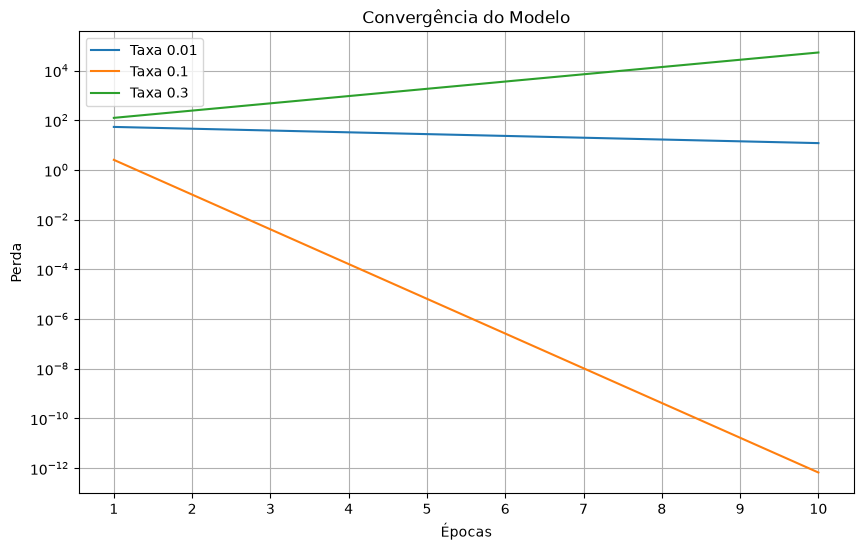

In [193]:
# Exercício 16 — Visualizando a convergência com Matplotlib

import matplotlib.pyplot as plt

# Implemente o gráfico seguindo estas etapas:

# 1. Crie uma figura com plt.figure(figsize=(10, 6)).
plt.figure(figsize=(10, 6))

# 2. Percorra o dicionário historicos usando for taxa, perdas in historicos.items().
for taxa, perdas in historicos.items():
    # 3. Para cada taxa, utilize plt.plot() para desenhar a evolução das perdas.
    plt.plot(range(1, epocas + 1), perdas, label=f'Taxa {taxa}')

# 4. Configure o eixo X com as épocas de 1 a 10.
plt.xticks(range(1, epocas + 1))

# 5. Adicione um título ao gráfico.
plt.title("Convergência do Modelo")

# 6. Identifique os eixos X e Y.
plt.xlabel("Épocas")
plt.ylabel("Perda")

# 7. Adicione uma legenda e uma grade.
plt.legend()
plt.grid(True)

# Desafio adicional: como as perdas da taxa 0.30 são muito maiores que as demais, experimente adicionar:
plt.yscale("log")

# 8. Utilize plt.show() para exibir o resultado.
plt.show()



## Exercício 17 — Early Stopping

**Objetivo e conteúdo observado no código:** Parada por limiar de perda ou outro critério explícito.

### Fundamentação conceitual

A interrupção antecipada evita iterações desnecessárias quando um critério é satisfeito.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Distinguir perda de treinamento e perda de validação ao interpretar o mecanismo.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [194]:
# Exercício 17 — Implementando Early Stopping

x = 2.0
y_real = 10.0

w = 1.0
learning_rate = 0.1

max_epocas = 100
tolerancia = 0.001

historico_perdas = []


# 1. Utilize um laço for com no máximo 100 épocas.
for epoca in range(max_epocas):
    # 2. Calcule a previsão, a perda e o gradiente.
    y_pred = w * x
    perda = (y_pred - y_real) ** 2
    gradiente = 2 * (y_pred - y_real) * x

    # 3. Atualize o peso utilizando Gradient Descent.
    w -= learning_rate * gradiente

    # 4. Calcule a perda correspondente ao peso atualizado.
    y_pred_atualizado = w * x
    perda_atualizada = (y_pred_atualizado - y_real) ** 2

    # 5. Armazene essa perda na lista historico_perdas.
    historico_perdas.append(perda_atualizada)

    # 6. Verifique se a perda atualizada é menor que tolerancia.
    if perda_atualizada < tolerancia:
        print(f"Treinamento interrompido na época {epoca + 1}")

        # 7. Utilize break para interromper o treinamento quando a condição for satisfeita.
        break

# 8. Exiba a época em que o treinamento terminou, o peso final, a previsão final e a perda final.
print(f"Época de término: {epoca + 1}")
print(f"Peso final: {w}")
print(f"Previsão final: {w * x}")
print(f"Perda final: {perda_atualizada}")


# Explique a diferença entre interromper o treinamento porque a perda atingiu uma tolerância e interrompê-lo porque a perda de validação deixou de melhorar.
# Interromper o treinamento porque a perda atingiu uma tolerância significa que o modelo alcançou um nível de desempenho satisfatório, e continuar treinando não traria melhorias significativas. Por outro lado, interromper o treinamento porque a perda de validação deixou de melhorar (early stopping) indica que o modelo pode estar começando a se ajustar demais aos dados de treinamento (overfitting), e continuar treinando poderia degradar seu desempenho em dados não vistos.

Treinamento interrompido na época 4
Época de término: 4
Peso final: 4.9936
Previsão final: 9.9872
Perda final: 0.00016384000000000938


## Exercício 18 — Early Stopping com paciência

**Objetivo e conteúdo observado no código:** Contagem de épocas consecutivas sem melhoria.

### Fundamentação conceitual

O parâmetro `patience` tolera flutuações temporárias antes de interromper o processo.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** A escolha da paciência influencia o momento da parada.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [195]:
# Exercício 18 — Early Stopping com paciência (patience)

perdas_validacao = [
    0.85, 0.62, 0.48, 0.39,
    0.35, 0.33, 0.34, 0.36,
    0.37, 0.38, 0.40
]

patience = 3

melhor_perda = float("inf")
epocas_sem_melhoria = 0
melhor_epoca = 0

# 1. Percorra a lista perdas_validacao utilizando enumerate(..., start=1).
for epoca, perda in enumerate(perdas_validacao, start=1):
    # 2. Compare a perda atual com melhor_perda.
    if perda < melhor_perda:
        # 3. Quando houver melhoria, atualize melhor_perda e melhor_epoca, zerando epocas_sem_melhoria.
        melhor_perda = perda
        melhor_epoca = epoca
        epocas_sem_melhoria = 0
    else:
        # 4. Quando não houver melhoria, incremente epocas_sem_melhoria.
        epocas_sem_melhoria += 1

    # 5. Interrompa o laço com break quando epocas_sem_melhoria >= patience.
    if epocas_sem_melhoria >= patience:
        print(f"Treinamento interrompido na época {epoca}")
        break

# 6. Exiba a época em que o treinamento foi interrompido, a melhor época e a menor perda de validação observada.
print(f"Época de término: {epoca}")
print(f"Melhor época: {melhor_epoca}")
print(f"Menor perda de validação: {melhor_perda}")

# Desafio adicional: explique por que é importante guardar os pesos correspondentes à melhor época de validação, em vez de utilizar automaticamente os pesos da última época executada.
# É importante guardar os pesos correspondentes à melhor época de validação porque esses pesos representam o ponto em que o modelo teve o melhor desempenho em dados não vistos. Se continuarmos treinando após essa época, o modelo pode começar a se ajustar demais aos dados de treinamento (overfitting), resultando em pior desempenho em novos dados. Portanto, utilizar os pesos da melhor época ajuda a garantir que o modelo generalize melhor para dados futuros.

Treinamento interrompido na época 9
Época de término: 9
Melhor época: 6
Menor perda de validação: 0.33


## Exercício 19 — Melhoria mínima no Early Stopping

**Objetivo e conteúdo observado no código:** Parâmetro `min_delta` para melhoria significativa.

### Fundamentação conceitual

Uma pequena redução numérica pode ser insuficiente para reiniciar a paciência.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Registrar a convenção de comparação utilizada.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [196]:
# Exercício 19 — Implementando min_delta no Early Stopping


perdas_validacao = [
    0.80, 0.60, 0.45, 0.38,
    0.350, 0.348, 0.347, 0.346,
    0.340, 0.339, 0.338
]

patience = 3
min_delta = 0.005

melhor_perda = float("inf")
melhor_epoca = 0
epocas_sem_melhoria = 0


# 1. Percorra as perdas usando enumerate(..., start=1).
for epoca, perda in enumerate(perdas_validacao, start=1):
    # 2. Considere uma melhoria significativa somente quando melhor_perda - perda > min_delta.
    if melhor_perda - perda > min_delta:
        # 3. Quando houver melhoria significativa, atualize melhor_perda e melhor_epoca e zere o contador.
        melhor_perda = perda
        melhor_epoca = epoca
        epocas_sem_melhoria = 0
    else:
        # 4. Caso contrário, incremente epocas_sem_melhoria.
        epocas_sem_melhoria += 1

    # 5. Interrompa o treinamento quando o contador atingir patience.
    if epocas_sem_melhoria >= patience:
        print(f"Treinamento interrompido na época {epoca}")
        break

# 6. Exiba a época de interrupção, a melhor época e a melhor perda registrada segundo esse critério.
print(f"Época de término: {epoca}")
print(f"Melhor época: {melhor_epoca}")
print(f"Melhor perda registrada: {melhor_perda}")

# Desafio adicional: explique a diferença entre a menor perda numérica observada e a melhor perda registrada pelo algoritmo quando utilizamos min_delta.
# A menor perda numérica observada é o valor mais baixo de perda que ocorreu durante o treinamento, independentemente de quão pequena seja a melhoria em relação à melhor perda anterior. Já a melhor perda registrada pelo algoritmo com min_delta considera apenas melhorias significativas, ou seja, aquelas que superam o limiar definido por min_delta. Portanto, a melhor perda registrada pode ser maior do que a menor perda numérica observada se as melhorias subsequentes forem menores que min_delta, indicando que o modelo não está melhorando de forma significativa.



Treinamento interrompido na época 8
Época de término: 8
Melhor época: 5
Melhor perda registrada: 0.35


## Exercício 20 — Checkpoint do melhor modelo

**Objetivo e conteúdo observado no código:** Seleção do estado associado à melhor perda observada.

### Fundamentação conceitual

Guardar o melhor estado permite recuperar parâmetros anteriores ao término do treinamento.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Verificar que os pesos persistidos correspondem à época selecionada.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [197]:
# Exercício 20 — Salvando o melhor modelo com checkpoint

pesos = [
    1.0, 1.8, 2.5, 3.1, 3.7,
    4.2, 4.5, 4.7, 4.8, 4.9
]

perdas_validacao = [
    0.90, 0.70, 0.50, 0.38, 0.29,
    0.24, 0.25, 0.27, 0.30, 0.33
]

patience = 3

melhor_perda = float("inf")
melhor_peso = None
melhor_epoca = 0
epocas_sem_melhoria = 0


# 1. Percorra as duas listas simultaneamente utilizando zip() e enumerate(..., start=1).
for epoca, (peso, perda) in enumerate(zip(pesos, perdas_validacao), start=1):
    # 2. Compare a perda atual com melhor_perda.
    if perda < melhor_perda:
        # 3. Quando encontrar uma perda menor, atualize melhor_perda, melhor_peso e melhor_epoca.
        melhor_perda = perda
        melhor_peso = peso
        melhor_epoca = epoca
        # 4. Reinicie o contador de épocas sem melhoria.
        epocas_sem_melhoria = 0
    else:
        # 5. Quando não houver melhoria, incremente o contador.
        epocas_sem_melhoria += 1

# 6. Interrompa o processamento quando epocas_sem_melhoria >= patience.
    # Dentro do laço for, após o if/else
    if epocas_sem_melhoria >= patience:
        print(f"Treinamento interrompido na época {epoca}")
        break

# 7. Exiba a época de interrupção, o último peso processado, a melhor época, o melhor peso e a menor perda de validação.
print(f"Época de término: {epoca}")
print(f"Último peso processado: {peso}")
print(f"Melhor época: {melhor_epoca}")
print(f"Melhor peso: {melhor_peso}")
print(f"Menor perda de validação: {melhor_perda}")

# Desafio adicional: explique por que, em um modelo com milhões de parâmetros, precisamos salvar todos os parâmetros treináveis relevantes, e não apenas um único peso.
# Em um modelo com milhões de parâmetros, cada parâmetro contribui para o desempenho geral do modelo. Salvar apenas um único peso não seria suficiente para reproduzir o comportamento do modelo, pois os outros parâmetros também influenciam as previsões. Portanto, é essencial salvar todos os parâmetros treináveis relevantes para garantir que o modelo possa ser restaurado e utilizado posteriormente com o mesmo desempenho observado durante o treinamento.

Treinamento interrompido na época 9
Época de término: 9
Último peso processado: 4.8
Melhor época: 6
Melhor peso: 4.2
Menor perda de validação: 0.24


## Exercício 21 — Checkpoint em JSON

**Objetivo e conteúdo observado no código:** Serialização, gravação e recuperação de parâmetros.

### Fundamentação conceitual

Um checkpoint documenta o estado do experimento e favorece rastreabilidade.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Validar tipos, campos e caminhos do arquivo antes da restauração.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [198]:
# Exercício 21 — Salvando e restaurando um checkpoint em JSON

import json
from pathlib import Path

# Diretório do projeto
diretorio_projeto = Path(
    r"C:\Engenharia-IA\01-Fundamentos-Python-ML"
)

# Diretório específico para checkpoints
diretorio_checkpoints = diretorio_projeto / "checkpoints"

# Criar a pasta caso ainda não exista
diretorio_checkpoints.mkdir(parents=True, exist_ok=True)

# Caminho completo do arquivo JSON
caminho_checkpoint = (
    diretorio_checkpoints / "checkpoint_exercicio21.json"
)

# Dados do melhor modelo
checkpoint = {
    "modelo": "RegressaoLinearSimulada",
    "melhor_epoca": melhor_epoca,
    "melhor_peso": melhor_peso,
    "melhor_perda": melhor_perda,
    "patience": patience
}

# Salvar o checkpoint
with open(caminho_checkpoint, "w", encoding="utf-8") as arquivo:
    json.dump(checkpoint, arquivo, indent=4)

# Restaurar o checkpoint
with open(caminho_checkpoint, "r", encoding="utf-8") as arquivo:
    checkpoint_restaurado = json.load(arquivo)

# Verificar os resultados
print("Arquivo salvo em:", caminho_checkpoint)
print("Modelo:", checkpoint_restaurado["modelo"])
print("Melhor época:", checkpoint_restaurado["melhor_epoca"])
print("Melhor peso:", checkpoint_restaurado["melhor_peso"])
print("Melhor perda:", checkpoint_restaurado["melhor_perda"])

print(
    "Checkpoint restaurado corretamente:",
    checkpoint_restaurado["melhor_peso"] == melhor_peso
)

# Desafio adicional: explique a diferença entre salvar um checkpoint em JSON e salvar os parâmetros de uma rede neural em um formato binário, como os utilizados pelo PyTorch.
# Salvar um checkpoint em JSON é útil para armazenar informações estruturadas e legíveis por humanos, como metadados, hiperparâmetros e resultados de treinamento. No entanto, JSON não é eficiente para armazenar grandes quantidades de dados numéricos, como os parâmetros de uma rede neural. Formatos binários, como os utilizados pelo PyTorch, são mais compactos e rápidos para leitura e escrita, permitindo salvar grandes tensores de forma eficiente e preservar a precisão dos valores numéricos.

Arquivo salvo em: C:\Engenharia-IA\01-Fundamentos-Python-ML\checkpoints\checkpoint_exercicio21.json
Modelo: RegressaoLinearSimulada
Melhor época: 6
Melhor peso: 4.2
Melhor perda: 0.24
Checkpoint restaurado corretamente: True


## Exercício 22 — Função reutilizável de treinamento

**Objetivo e conteúdo observado no código:** Parâmetros configuráveis, histórico, critérios de parada e retorno estruturado.

### Fundamentação conceitual

Encapsular o treinamento em uma função reduz repetição e favorece testes isolados.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Verificar a consistência entre `peso_final`, `previsao_final`, `perda_final` e `historico_perdas`.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [199]:
# Próxima etapa — Exercício 22: Organizando o treinamento em funções


def treinar_modelo(
    x,
    y_real,
    peso_inicial=1.0,
    learning_rate=0.1,
    max_epocas=100,
    tolerancia=0.001
):
    # 1. Inicializar as variáveis
    w = peso_inicial
    historico_perdas = []

    # 2. Executar o treinamento
    for epoca in range(max_epocas):
        # Calcular previsão e perda
        y_previsto = w * x
        perda = (y_previsto - y_real) ** 2

        # Calcular o gradiente
        gradiente = 2 * x * (y_previsto - y_real)

        # Atualizar o peso uma única vez
        w = w - learning_rate * gradiente

        # Calcular a perda com o peso atualizado
        previsao_atualizada = w * x
        perda_atualizada = (previsao_atualizada - y_real) ** 2

        # Registrar o histórico
        historico_perdas.append(perda_atualizada)

        # Aplicar Early Stopping
        if perda_atualizada < tolerancia:
            break

    # 3. Calcular os resultados finais
    previsao_final = w * x
    perda_final = (previsao_final - y_real) ** 2

    # 4. Retornar os resultados
    return {
        "peso_final": w,
        "previsao_final": previsao_final,
        "perda_final": perda_final,
        "epocas_executadas": len(historico_perdas),
        "historico_perdas": historico_perdas
    }




resultado = treinar_modelo(
    x=2.0,
    y_real=10.0,
    learning_rate=0.1,
    tolerancia=0.001
)

print(f"Peso final: {resultado['peso_final']:.4f}")
print(f"Previsão final: {resultado['previsao_final']:.4f}")
print(f"Perda final: {resultado['perda_final']:.6f}")
print(f"Épocas executadas: {resultado['epocas_executadas']}")
print(f"Histórico de perdas: {resultado['historico_perdas']}")



Peso final: 4.9936
Previsão final: 9.9872
Perda final: 0.000164
Épocas executadas: 4
Histórico de perdas: [2.5599999999999987, 0.10240000000000019, 0.004096000000000008, 0.00016384000000000938]


## Exercício 23 — Testes automatizados

**Objetivo e conteúdo observado no código:** Asserções sobre retorno, peso, épocas, perda e histórico.

### Fundamentação conceitual

Testes de unidade verificam propriedades observáveis da implementação em condições controladas.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Aprovação em casos específicos não equivale a validação universal.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [200]:
# Exercício 23 — Testes automatizados

# Executar o treinamento
resultado = treinar_modelo(
    x=2.0,
    y_real=10.0,
    peso_inicial=1.0,
    learning_rate=0.1,
    max_epocas=100,
    tolerancia=0.001
)

# Teste 1 — Verificar se o resultado é um dicionário
assert isinstance(resultado, dict)

# Teste 2 — Verificar o peso final
assert abs(resultado["peso_final"] - 4.9936) < 1e-4

# Teste 3 — Verificar o número de épocas
assert resultado["epocas_executadas"] == 4

# Teste 4 — Verificar a perda final
assert resultado["perda_final"] < 0.001

# Teste 5 — Verificar o histórico de perdas
assert len(resultado["historico_perdas"]) == resultado["epocas_executadas"]

print("Todos os testes passaram com sucesso!")


Todos os testes passaram com sucesso!


## Exercício 26 — Vetorização e desempenho

**Objetivo e conteúdo observado no código:** Comparação de cálculo com laços Python e NumPy, incluindo `timeit`.

### Fundamentação conceitual

A vetorização desloca operações numéricas para rotinas otimizadas; medições de tempo devem usar cargas equivalentes.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Tempos dependem do ambiente, tamanho dos dados e metodologia de medição.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [201]:
# Exercício 26 — Vetorização NumPy e desempenho computacional
# Etapa 1 — Verificar a equivalência dos cálculos

import numpy as np

# Quantidade de equipamentos
quantidade = 1_000_000

# Potência em kW e tempo em horas
potencias = np.full(quantidade, 2.0)
horas = np.full(quantidade, 5.0)

# Implementação tradicional em Python
def calcular_consumo_python():
    consumos = []

    for i in range(quantidade):
        consumo = potencias[i] * horas[i]
        consumos.append(consumo)

    return consumos


# Implementação vetorizada com NumPy
def calcular_consumo_numpy():
    return potencias * horas


# Executar as duas implementações
resultado_python = calcular_consumo_python()
resultado_numpy = calcular_consumo_numpy()

# Validar os resultados
print("Resultados equivalentes:",
      np.allclose(resultado_python, resultado_numpy))

print("Consumo total Python:",
      sum(resultado_python), "kWh")

print("Consumo total NumPy:",
      np.sum(resultado_numpy), "kWh")


Resultados equivalentes: True
Consumo total Python: 10000000.0 kWh
Consumo total NumPy: 10000000.0 kWh


In [202]:
# Exercício 26 — Etapa 2: medição de desempenho com timeit

import timeit

# Medir a implementação tradicional
tempos_python = timeit.repeat(
    calcular_consumo_python,
    repeat=5,
    number=3
)

# Medir a implementação vetorizada
tempos_numpy = timeit.repeat(
    calcular_consumo_numpy,
    repeat=5,
    number=3
)

# Melhor tempo médio por execução
tempo_python = min(tempos_python) / 3
tempo_numpy = min(tempos_numpy) / 3

# Comparar desempenho
fator_aceleracao = tempo_python / tempo_numpy

print(f"Python tradicional: {tempo_python:.6f} segundos")
print(f"NumPy vetorizado:   {tempo_numpy:.6f} segundos")
print(f"Fator de aceleração: {fator_aceleracao:.2f} vezes")


Python tradicional: 0.260987 segundos
NumPy vetorizado:   0.002579 segundos
Fator de aceleração: 101.20 vezes


## Exercício 27 — Norma e projeção vetorial

**Objetivo e conteúdo observado no código:** Norma Euclidiana, produto escalar e decomposição em componente projetada e perpendicular.

### Fundamentação conceitual

A norma L2 mede o comprimento do vetor; a projeção expressa a componente de um vetor na direção de outro.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** A projeção requer vetor de referência não nulo; confirmar reconstrução e ortogonalidade.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [203]:
# Exercício 27 —  Etapa 1 — Calcular a norma de um vetor
import numpy as np

# Vetor representando três medições
consumo = np.array([3.0, 4.0, 12.0])

# Calcular manualmente a norma L2
norma_manual = np.sqrt(np.sum(consumo ** 2))

# Calcular usando álgebra linear do NumPy
norma_numpy = np.linalg.norm(consumo)

print(f"Norma manual: {norma_manual:.4f}")
print(f"Norma NumPy:  {norma_numpy:.4f}")
print("Resultados equivalentes:",
      np.isclose(norma_manual, norma_numpy))


Norma manual: 13.0000
Norma NumPy:  13.0000
Resultados equivalentes: True


> **Nota de auditoria do arquivo anexado:** a célula de projeção vetorial abaixo possui uma saída do tipo `error` no arquivo recebido. Ela foi preservada integralmente para investigação; não considerar esta execução como aprovada até nova validação.


In [205]:
 #Exercício 27 — Etapa 2: projeção vetorial

import numpy as np

# Vetores de exemplo
a = np.array([3.0, 4.0])
b = np.array([1.0, 0.0])

# Produto escalar
produto_escalar = np.dot(a, b)

# Norma de b ao quadrado
norma_b_quadrado = np.dot(b, b)

# Projeção de a sobre b
projecao = (produto_escalar / norma_b_quadrado) * b

# Componente perpendicular
componente_perpendicular = a - projecao

print("Vetor a:", a)
print("Vetor b:", b)
print("Produto escalar:", produto_escalar)
print("Projeção de a sobre b:", projecao)
print("Componente perpendicular:", componente_perpendicular)
print("Reconstrução correta:",
      np.allclose(projecao + componente_perpendicular, a))


Vetor a: [3. 4.]
Vetor b: [1. 0.]
Produto escalar: 3.0
Projeção de a sobre b: [3. 0.]
Componente perpendicular: [0. 4.]
Reconstrução correta: True


## Exercício 28 — Regressão linear por álgebra matricial

**Objetivo e conteúdo observado no código:** Matriz de projeto, mínimos quadrados, coeficientes e previsões.

### Fundamentação conceitual

A regressão ajusta coeficientes para minimizar a soma dos resíduos quadráticos.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Erro zero nos dados demonstrativos não implica desempenho perfeito em produção.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [ ]:
# Exercício 28 — Regressão linear com álgebra matricial
# Etapa 1 — Implementação

import numpy as np

# Horas de funcionamento dos equipamentos
horas = np.array([1, 2, 3, 4, 5], dtype=float)

# Consumo energético em kWh
consumo = np.array([3, 5, 7, 9, 11], dtype=float)

# Construir a matriz de características
X = np.column_stack([
    np.ones(len(horas)),
    horas
])

# Calcular os coeficientes por mínimos quadrados
coeficientes, residuos, posto, valores_singulares = (
    np.linalg.lstsq(X, consumo, rcond=None)
)

# Separar os coeficientes
beta_0, beta_1 = coeficientes

# Realizar previsões
previsoes = X @ coeficientes

# Calcular o erro quadrático médio
mse = np.mean((consumo - previsoes) ** 2)

print("Formato da matriz X:", X.shape)
print(f"Intercepto: {beta_0:.4f}")
print(f"Coeficiente angular: {beta_1:.4f}")
print("Previsões:", previsoes)
print(f"Erro quadrático médio: {mse:.8f}")
print("Posto da matriz:", posto)


In [ ]:
# Exercício 28 — Etapa 2: validar as previsões


# Novos valores de horas
novas_horas = np.array([6.0, 8.0, 10.0])

# Construir a matriz para previsão
X_novo = np.column_stack([
    np.ones(len(novas_horas)),
    novas_horas
])

# Gerar previsões com o modelo treinado
novas_previsoes = X_novo @ coeficientes

# Valores esperados pela relação y = 1 + 2x
valores_esperados = 1 + 2 * novas_horas

print("Novas horas:", novas_horas)
print("Consumo previsto:", novas_previsoes)
print("Valores esperados:", valores_esperados)
print("Previsões corretas:",
      np.allclose(novas_previsoes, valores_esperados))


## Exercício 29 — Estatística descritiva e outliers

**Objetivo e conteúdo observado no código:** Medidas de tendência central e dispersão; quartis, IQR e Z-score.

### Fundamentação conceitual

IQR identifica valores fora de limites derivados de quartis; Z-score padroniza desvios em relação à média.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Os métodos possuem pressupostos e sensibilidades diferentes; um outlier não é necessariamente um erro.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [ ]:
# Exercício 29: Estatística descritiva aplicada ao consumo energético
# Etapa 1 — Implementação com NumPy

import numpy as np

# Consumo diário de 10 equipamentos (kWh)
consumos = np.array([
    120, 135, 128, 140, 132,
    125, 138, 130, 145, 127
], dtype=float)

# Calcular estatísticas descritivas
media = np.mean(consumos)
mediana = np.median(consumos)
desvio_padrao = np.std(consumos)
minimo = np.min(consumos)
maximo = np.max(consumos)

# Apresentar resultados
print(f"Média: {media:.2f} kWh")
print(f"Mediana: {mediana:.2f} kWh")
print(f"Desvio padrão: {desvio_padrao:.2f} kWh")
print(f"Mínimo: {minimo:.2f} kWh")
print(f"Máximo: {maximo:.2f} kWh")



In [ ]:
# Exercício 29 — Etapa 2
# Quartis e intervalo interquartil

q1 = np.percentile(consumos, 25)
q2 = np.percentile(consumos, 50)
q3 = np.percentile(consumos, 75)

iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

print(f"Primeiro quartil (Q1): {q1:.2f} kWh")
print(f"Segundo quartil (Q2): {q2:.2f} kWh")
print(f"Terceiro quartil (Q3): {q3:.2f} kWh")
print(f"Intervalo interquartil: {iqr:.2f} kWh")
print(f"Limite inferior: {limite_inferior:.2f} kWh")
print(f"Limite superior: {limite_superior:.2f} kWh")


In [ ]:
# Exercício 29 — Etapa 3
# Detecção automática de outliers pelo IQR

# Identificar valores fora dos limites
mascara_outliers = (
    (consumos < limite_inferior) |
    (consumos > limite_superior)
)

# Selecionar os valores identificados
outliers = consumos[mascara_outliers]

# Contar os valores atípicos
quantidade_outliers = len(outliers)

print("Consumos analisados:", consumos)
print("Outliers identificados:", outliers)
print("Quantidade de outliers:", quantidade_outliers)
print("Nenhum outlier encontrado:",
      quantidade_outliers == 0)


In [ ]:
# Exercício 29 — Etapa 4
# Simulação de consumo energético anormal

import numpy as np

# Criar uma cópia dos dados originais
consumos_anormais = consumos.copy()

# Simular consumo excessivo no último equipamento
consumos_anormais[-1] = 350.0

# Recalcular os quartis
q1_anormal = np.percentile(consumos_anormais, 25)
q3_anormal = np.percentile(consumos_anormais, 75)

# Recalcular o intervalo interquartil
iqr_anormal = q3_anormal - q1_anormal

# Estabelecer novos limites
limite_inferior_anormal = q1_anormal - 1.5 * iqr_anormal
limite_superior_anormal = q3_anormal + 1.5 * iqr_anormal

# Identificar outliers
mascara_anormais = (
    (consumos_anormais < limite_inferior_anormal) |
    (consumos_anormais > limite_superior_anormal)
)

outliers_anormais = consumos_anormais[mascara_anormais]

# Exibir resultados
print("Consumos:", consumos_anormais)
print(f"Limite inferior: {limite_inferior_anormal:.2f} kWh")
print(f"Limite superior: {limite_superior_anormal:.2f} kWh")
print("Outliers identificados:", outliers_anormais)
print("Quantidade de outliers:", len(outliers_anormais))


In [ ]:

# Exercício 29 — Etapa 5
# Detecção de anomalias utilizando Z-score

import numpy as np

# Utilizar os dados com consumo anormal
dados = consumos_anormais.copy()

# Calcular média e desvio padrão
media = np.mean(dados)
desvio = np.std(dados)

# Calcular Z-score de cada equipamento
z_scores = (dados - media) / desvio

# Identificar possíveis outliers
limiar_z = 3.0
mascara_z = np.abs(z_scores) > limiar_z

outliers_z = dados[mascara_z]

print(f"Média: {media:.2f} kWh")
print(f"Desvio padrão: {desvio:.2f} kWh")
print("Z-scores:", np.round(z_scores, 2))
print("Outliers pelo Z-score:", outliers_z)
print("Quantidade de outliers:", len(outliers_z))


In [ ]:

# Exercício 29 — Etapa 6
# Influência de um outlier nas estatísticas

media_original = np.mean(consumos)
desvio_original = np.std(consumos)

media_anormal = np.mean(consumos_anormais)
desvio_anormal = np.std(consumos_anormais)

print(f"Média original: {media_original:.2f} kWh")
print(f"Média com outlier: {media_anormal:.2f} kWh")

print(f"Desvio padrão original: {desvio_original:.2f} kWh")
print(f"Desvio padrão com outlier: {desvio_anormal:.2f} kWh")

print(f"Aumento da média: {media_anormal - media_original:.2f} kWh")
print(f"Aumento do desvio padrão: {desvio_anormal - desvio_original:.2f} kWh")


## Exercício 30 — Distribuições e intervalos de confiança

**Objetivo e conteúdo observado no código:** Simulações normal/lognormal, intervalos e visualização.

### Fundamentação conceitual

A distribuição normal é simétrica; a lognormal é assimétrica e estritamente positiva. Intervalos estimam incerteza sob hipóteses explícitas.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Interpretar corretamente o nível de confiança e verificar pressupostos.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [ ]:

# Exercício 30 — Etapa 1
# Simulação de consumo energético com distribuição normal

import numpy as np

# Gerador aleatório com semente fixa
rng = np.random.default_rng(seed=42)

# Parâmetros da distribuição
media_teorica = 150.0
desvio_teorico = 20.0
quantidade_amostras = 1000

# Gerar os consumos simulados
consumos_simulados = rng.normal(
    loc=media_teorica,
    scale=desvio_teorico,
    size=quantidade_amostras
)

# Calcular estatísticas da amostra
media_amostral = np.mean(consumos_simulados)
desvio_amostral = np.std(consumos_simulados, ddof=1)

print("Quantidade de amostras:", len(consumos_simulados))
print(f"Média teórica: {media_teorica:.2f} kWh")
print(f"Média amostral: {media_amostral:.2f} kWh")
print(f"Desvio padrão teórico: {desvio_teorico:.2f} kWh")
print(f"Desvio padrão amostral: {desvio_amostral:.2f} kWh")


In [ ]:

# Exercício 30 — Etapa 2
# Intervalo de confiança de 95% para a média

import numpy as np
from scipy import stats

# Estatísticas da amostra
n = len(consumos_simulados)
media = np.mean(consumos_simulados)
desvio = np.std(consumos_simulados, ddof=1)

# Nível de confiança
confianca = 0.95
alpha = 1 - confianca

# Erro padrão da média
erro_padrao = desvio / np.sqrt(n)

# Valor crítico t de Student
t_critico = stats.t.ppf(1 - alpha / 2, df=n - 1)

# Margem de erro
margem_erro = t_critico * erro_padrao

# Limites do intervalo
limite_inferior = media - margem_erro
limite_superior = media + margem_erro

print(f"Tamanho da amostra: {n}")
print(f"Média amostral: {media:.2f} kWh")
print(f"Erro padrão: {erro_padrao:.4f} kWh")
print(f"Valor crítico t: {t_critico:.4f}")
print(f"Margem de erro: {margem_erro:.4f} kWh")
print(f"IC 95%: [{limite_inferior:.2f}, {limite_superior:.2f}] kWh")
print("Contém a média teórica:",
      limite_inferior <= media_teorica <= limite_superior)


In [ ]:

# Exercício 30 — Etapa 3
# Comparação entre distribuições normal e lognormal

import numpy as np
from scipy.stats import skew

# Gerador independente e reproduzível
rng_comparacao = np.random.default_rng(seed=123)

# Distribuição normal
dados_normais = rng_comparacao.normal(
    loc=150,
    scale=20,
    size=1000
)

# Distribuição lognormal
dados_assimetricos = rng_comparacao.lognormal(
    mean=5.0,
    sigma=0.5,
    size=1000
)

# Calcular estatísticas
for nome, dados in [
    ("Normal", dados_normais),
    ("Lognormal", dados_assimetricos)
]:
    print(f"\nDistribuição: {nome}")
    print(f"Média: {np.mean(dados):.2f}")
    print(f"Mediana: {np.median(dados):.2f}")
    print(f"Desvio padrão: {np.std(dados, ddof=1):.2f}")
    print(f"Assimetria: {skew(dados):.4f}")


In [ ]:

# Exercício 30 — Etapa 4
# Visualização das distribuições

import matplotlib.pyplot as plt

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

# Histograma da distribuição normal
eixos[0].hist(
    dados_normais,
    bins=30,
    edgecolor="black"
)
eixos[0].axvline(
    np.mean(dados_normais),
    linestyle="--",
    label="Média"
)
eixos[0].set_title("Distribuição Normal")
eixos[0].set_xlabel("Consumo energético")
eixos[0].set_ylabel("Frequência")
eixos[0].legend()

# Histograma da distribuição lognormal
eixos[1].hist(
    dados_assimetricos,
    bins=30,
    edgecolor="black"
)
eixos[1].axvline(
    np.mean(dados_assimetricos),
    linestyle="--",
    label="Média"
)
eixos[1].set_title("Distribuição Lognormal")
eixos[1].set_xlabel("Consumo energético")
eixos[1].set_ylabel("Frequência")
eixos[1].legend()

plt.tight_layout()
plt.show()


In [ ]:

# Exercício 30 — Etapa 5
# Comparação visual entre média e mediana

import matplotlib.pyplot as plt
import numpy as np

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

distribuicoes = [
    ("Normal", dados_normais),
    ("Lognormal", dados_assimetricos)
]

for eixo, (nome, dados) in zip(eixos, distribuicoes):
    media = np.mean(dados)
    mediana = np.median(dados)

    eixo.hist(dados, bins=30, edgecolor="black")

    eixo.axvline(
        media,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Média: {media:.2f}"
    )

    eixo.axvline(
        mediana,
        color="green",
        linestyle="-",
        linewidth=2,
        label=f"Mediana: {mediana:.2f}"
    )

    eixo.set_title(f"Distribuição {nome}")
    eixo.set_xlabel("Consumo energético (kWh)")
    eixo.set_ylabel("Frequência")
    eixo.legend()

plt.tight_layout()
plt.show()


## Exercício 31 — Comparação de detectores estatísticos

**Objetivo e conteúdo observado no código:** IQR, Z-score, matriz de concordância e índice de Jaccard.

### Fundamentação conceitual

Jaccard mede a razão entre interseção e união dos conjuntos sinalizados.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Concordância entre métodos não estabelece a existência de anomalias reais.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [ ]:

# Exercício 31 — Etapa 1
# Detecção de valores extremos usando IQR

import numpy as np

# Quartis
q1 = np.percentile(dados_assimetricos, 25)
q3 = np.percentile(dados_assimetricos, 75)

# Intervalo interquartil
iqr = q3 - q1

# Limites para detecção
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Identificação dos valores extremos
valores_extremos = dados_assimetricos[
    (dados_assimetricos < limite_inferior) |
    (dados_assimetricos > limite_superior)
]

print(f"Q1: {q1:.2f} kWh")
print(f"Q3: {q3:.2f} kWh")
print(f"IQR: {iqr:.2f} kWh")
print(f"Limite inferior: {limite_inferior:.2f} kWh")
print(f"Limite superior: {limite_superior:.2f} kWh")
print(f"Quantidade de valores extremos: {len(valores_extremos)}")
print(f"Percentual de valores extremos: {len(valores_extremos) / len(dados_assimetricos) * 100:.2f}%")


In [ ]:

# Exercício 31 — Etapa 2
# Comparação entre IQR e Z-score

import numpy as np

# Média e desvio padrão da distribuição lognormal
media = np.mean(dados_assimetricos)
desvio = np.std(dados_assimetricos, ddof=1)

# Calcular Z-score
z_scores = (dados_assimetricos - media) / desvio

# Identificar valores com |Z| > 3
mascara_zscore = np.abs(z_scores) > 3
valores_extremos_zscore = dados_assimetricos[mascara_zscore]

# Recuperar os valores sinalizados pelo IQR
mascara_iqr = (
    (dados_assimetricos < limite_inferior) |
    (dados_assimetricos > limite_superior)
)

# Comparar as classificações
detectados_ambos = np.sum(mascara_iqr & mascara_zscore)
somente_iqr = np.sum(mascara_iqr & ~mascara_zscore)
somente_zscore = np.sum(~mascara_iqr & mascara_zscore)

print(f"Média: {media:.2f} kWh")
print(f"Desvio padrão: {desvio:.2f} kWh")
print(f"Detectados pelo IQR: {np.sum(mascara_iqr)}")
print(f"Detectados pelo Z-score: {np.sum(mascara_zscore)}")
print(f"Detectados por ambos: {detectados_ambos}")
print(f"Detectados somente pelo IQR: {somente_iqr}")
print(f"Detectados somente pelo Z-score: {somente_zscore}")


In [ ]:

# Exercício 31 — Etapa 3
# Matriz de concordância entre IQR e Z-score

import numpy as np

# Classificações dos dois métodos
ambos_normais = np.sum(~mascara_iqr & ~mascara_zscore)
somente_iqr = np.sum(mascara_iqr & ~mascara_zscore)
somente_zscore = np.sum(~mascara_iqr & mascara_zscore)
ambos_extremos = np.sum(mascara_iqr & mascara_zscore)

# Total de observações
total = len(dados_assimetricos)

# Concordância global
concordancia = (
    ambos_normais + ambos_extremos
) / total * 100

print("Matriz de concordância")
print(f"Normais para ambos: {ambos_normais}")
print(f"Extremos somente no IQR: {somente_iqr}")
print(f"Extremos somente no Z-score: {somente_zscore}")
print(f"Extremos para ambos: {ambos_extremos}")
print(f"Total analisado: {total}")
print(f"Concordância global: {concordancia:.2f}%")


In [ ]:

# Exercício 31 — Etapa 4
# Índice de Jaccard entre IQR e Z-score

import numpy as np

# Interseção: valores sinalizados pelos dois métodos
intersecao = np.sum(mascara_iqr & mascara_zscore)

# União: valores sinalizados por pelo menos um método
uniao = np.sum(mascara_iqr | mascara_zscore)

# Índice de Jaccard
jaccard = intersecao / uniao if uniao > 0 else 1.0

print(f"Interseção: {intersecao}")
print(f"União: {uniao}")
print(f"Índice de Jaccard: {jaccard:.4f}")
print(f"Similaridade percentual: {jaccard * 100:.2f}%")


## Exercício 32 — Amostragem e Teorema Central do Limite

**Objetivo e conteúdo observado no código:** Tamanho amostral, variabilidade da média e repetição de amostras.

### Fundamentação conceitual

A distribuição de médias amostrais tende à normalidade sob condições apropriadas, mesmo com população assimétrica.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** O tamanho da amostra influencia o erro padrão; não elimina vieses de coleta.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [ ]:

# Exercício 32 — Etapa 1
# Influência do tamanho da amostra na estimativa da média

import numpy as np

rng = np.random.default_rng(seed=2026)

media_populacional = 150.0
desvio_populacional = 20.0

tamanhos = [10, 30, 100, 1000]

for n in tamanhos:
    amostra = rng.normal(
        loc=media_populacional,
        scale=desvio_populacional,
        size=n
    )

    media_amostral = np.mean(amostra)
    erro_absoluto = abs(media_amostral - media_populacional)
    erro_padrao_estimado = np.std(amostra, ddof=1) / np.sqrt(n)

    print(f"\nTamanho da amostra: {n}")
    print(f"Média amostral: {media_amostral:.2f} kWh")
    print(f"Erro absoluto: {erro_absoluto:.2f} kWh")
    print(f"Erro padrão estimado: {erro_padrao_estimado:.4f} kWh")


In [ ]:

# Exercício 32 — Etapa 2
# Variabilidade das médias em amostragens repetidas

import numpy as np

rng_repeticoes = np.random.default_rng(seed=2026)

media_populacional = 150.0
desvio_populacional = 20.0

tamanhos = [10, 30, 100, 1000]
repeticoes = 1000

for n in tamanhos:

    # Gerar 1.000 amostras independentes de tamanho n
    amostras = rng_repeticoes.normal(
        loc=media_populacional,
        scale=desvio_populacional,
        size=(repeticoes, n)
    )

    # Calcular a média de cada amostra
    medias_amostrais = np.mean(amostras, axis=1)

    # Estatísticas das médias obtidas
    media_das_medias = np.mean(medias_amostrais)
    desvio_das_medias = np.std(medias_amostrais, ddof=1)

    # Erro padrão teórico
    erro_padrao_teorico = desvio_populacional / np.sqrt(n)

    print(f"\nTamanho da amostra: {n}")
    print(f"Média das médias: {media_das_medias:.2f} kWh")
    print(f"Desvio das médias: {desvio_das_medias:.4f} kWh")
    print(f"Erro padrão teórico: {erro_padrao_teorico:.4f} kWh")


In [ ]:

# Exercício 32 — Etapa 3
# Teorema Central do Limite com população assimétrica

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew

rng_tcl = np.random.default_rng(seed=2026)

tamanhos = [1, 5, 30, 100]
repeticoes = 5000

fig, eixos = plt.subplots(2, 2, figsize=(12, 8))

for eixo, n in zip(eixos.flat, tamanhos):

    # Amostras de uma distribuição lognormal assimétrica
    amostras = rng_tcl.lognormal(
        mean=5.0,
        sigma=0.5,
        size=(repeticoes, n)
    )

    # Média de cada amostra
    medias = np.mean(amostras, axis=1)

    # Assimetria das médias amostrais
    assimetria = skew(medias)

    eixo.hist(medias, bins=40, edgecolor="black")
    eixo.set_title(f"n = {n} | Assimetria = {assimetria:.3f}")
    eixo.set_xlabel("Média amostral (kWh)")
    eixo.set_ylabel("Frequência")

    print(f"n = {n} | Assimetria = {assimetria:.4f}")

plt.tight_layout()
plt.show()


## Exercício 33 — Experimento de auditoria energética

**Objetivo e conteúdo observado no código:** Dados sintéticos, regressão, resíduos, testes diagnósticos, validação temporal e baseline.

### Fundamentação conceitual

Uma avaliação walk-forward treina apenas com dados anteriores a cada previsão, reduzindo vazamento temporal.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Resultados de previsão não representam economia de energia; diagnósticos estatísticos e dados sintéticos limitam generalização.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [ ]:

# Exercício 33 — Etapa 1
# Construção de um conjunto de dados de consumo energético

import numpy as np
import pandas as pd

rng = np.random.default_rng(seed=2026)

# Período de 30 dias
datas = pd.date_range(
    start="2026-09-01",
    periods=30,
    freq="D"
)

# Horas de operação por dia
horas_operacao = rng.integers(
    low=6,
    high=13,
    size=30
)

# Consumo estimado: parcela fixa + consumo por hora + ruído
consumo_kwh = (
    50
    + 18 * horas_operacao
    + rng.normal(0, 12, size=30)
)

# Criar DataFrame
df_energia = pd.DataFrame({
    "data": datas,
    "horas_operacao": horas_operacao,
    "consumo_kwh": consumo_kwh
})

# Exibir informações iniciais
print("Dimensões:", df_energia.shape)
print("\nTipos de dados:")
print(df_energia.dtypes)

print("\nPrimeiras cinco observações:")
print(df_energia.head())

print("\nValores ausentes:")
print(df_energia.isnull().sum())


In [ ]:

# Exercício 33 — Etapa 2
# Análise estatística descritiva do consumo energético

import numpy as np

# Estatísticas das horas de operação
media_horas = df_energia["horas_operacao"].mean()
min_horas = df_energia["horas_operacao"].min()
max_horas = df_energia["horas_operacao"].max()

# Estatísticas do consumo energético
media_consumo = df_energia["consumo_kwh"].mean()
mediana_consumo = df_energia["consumo_kwh"].median()
desvio_consumo = df_energia["consumo_kwh"].std()

min_consumo = df_energia["consumo_kwh"].min()
max_consumo = df_energia["consumo_kwh"].max()

# Consumo total no período
consumo_total = df_energia["consumo_kwh"].sum()

print("=== HORAS DE OPERAÇÃO ===")
print(f"Média: {media_horas:.2f} horas")
print(f"Mínimo: {min_horas} horas")
print(f"Máximo: {max_horas} horas")

print("\n=== CONSUMO ENERGÉTICO ===")
print(f"Média: {media_consumo:.2f} kWh")
print(f"Mediana: {mediana_consumo:.2f} kWh")
print(f"Desvio padrão: {desvio_consumo:.2f} kWh")
print(f"Mínimo: {min_consumo:.2f} kWh")
print(f"Máximo: {max_consumo:.2f} kWh")
print(f"Consumo total: {consumo_total:.2f} kWh")


In [ ]:

# Exercício 33 — Etapa 3
# Correlação entre horas de operação e consumo energético

import numpy as np
import matplotlib.pyplot as plt

# Selecionar as variáveis
horas = df_energia["horas_operacao"].to_numpy()
consumo = df_energia["consumo_kwh"].to_numpy()

# Calcular a correlação de Pearson
correlacao = np.corrcoef(horas, consumo)[0, 1]

print(f"Correlação de Pearson: {correlacao:.4f}")

# Criar gráfico de dispersão
plt.figure(figsize=(9, 5))

plt.scatter(
    horas,
    consumo,
    alpha=0.8,
    label="Consumo observado"
)

plt.title("Horas de operação × Consumo energético")
plt.xlabel("Horas de operação por dia")
plt.ylabel("Consumo diário (kWh)")
plt.grid(alpha=0.3)
plt.legend()

plt.show()


In [ ]:
# Confirmação da correlação
print(f"Correlação de Pearson: {correlacao:.4f}")

In [ ]:

# Exercício 33 — Etapa 4
# Regressão linear usando mínimos quadrados

import numpy as np

# Variáveis independentes e dependentes
x = df_energia["horas_operacao"].to_numpy()
y = df_energia["consumo_kwh"].to_numpy()

# Matriz de projeto: intercepto + horas de operação
X = np.column_stack([
    np.ones(len(x)),
    x
])

# Ajustar os coeficientes
coeficientes, residuos, posto, valores_singulares = (
    np.linalg.lstsq(X, y, rcond=None)
)

intercepto, coeficiente_horas = coeficientes

# Calcular previsões
y_previsto = X @ coeficientes

# Calcular métricas
mse = np.mean((y - y_previsto) ** 2)
rmse = np.sqrt(mse)

soma_quadrados_residuos = np.sum((y - y_previsto) ** 2)
soma_quadrados_total = np.sum((y - np.mean(y)) ** 2)

r2 = 1 - soma_quadrados_residuos / soma_quadrados_total

print(f"Intercepto estimado: {intercepto:.4f}")
print(f"Coeficiente das horas: {coeficiente_horas:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f} kWh")
print(f"R²: {r2:.4f}")
print(f"Posto da matriz: {posto}")


In [ ]:

# Exercício 33 — Etapa 5
# Análise dos resíduos da regressão linear

import numpy as np
import pandas as pd

# Calcular resíduos
residuos_modelo = y - y_previsto

# Criar tabela de análise
df_residuos = df_energia.copy()

df_residuos["consumo_previsto"] = y_previsto
df_residuos["residuo"] = residuos_modelo
df_residuos["erro_absoluto"] = np.abs(residuos_modelo)

# Estatísticas dos resíduos
media_residuos = np.mean(residuos_modelo)
desvio_residuos = np.std(residuos_modelo, ddof=1)
maior_erro = np.max(np.abs(residuos_modelo))

print(f"Média dos resíduos: {media_residuos:.6f} kWh")
print(f"Desvio padrão dos resíduos: {desvio_residuos:.4f} kWh")
print(f"Maior erro absoluto: {maior_erro:.4f} kWh")

print("\n=== CINCO MAIORES DESVIOS ===")

print(
    df_residuos.nlargest(5, "erro_absoluto")[
        [
            "data",
            "horas_operacao",
            "consumo_kwh",
            "consumo_previsto",
            "residuo"
        ]
    ].round(2).to_string(index=False)
)


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 5
# Análise dos resíduos da regressão linear
# Versão corrigida — sem aviso do Pandas
# ============================================================

import numpy as np
import pandas as pd

# 1. Calcular os resíduos do modelo
# Resíduo = consumo observado - consumo previsto
residuos_modelo = y - y_previsto

# 2. Criar uma cópia do DataFrame original
df_residuos = df_energia.copy()

# 3. Adicionar as previsões e os resíduos
df_residuos["consumo_previsto"] = y_previsto
df_residuos["residuo"] = residuos_modelo

# 4. Calcular o erro absoluto
df_residuos["erro_absoluto"] = np.abs(residuos_modelo)

# 5. Calcular as estatísticas dos resíduos
media_residuos = np.mean(residuos_modelo)
desvio_residuos = np.std(residuos_modelo, ddof=1)
maior_erro = np.max(np.abs(residuos_modelo))

# 6. Exibir as estatísticas
print("=== ESTATÍSTICAS DOS RESÍDUOS ===")

print(f"Média dos resíduos: {media_residuos:.6f} kWh")
print(f"Desvio padrão dos resíduos: {desvio_residuos:.4f} kWh")
print(f"Maior erro absoluto: {maior_erro:.4f} kWh")

# 7. Selecionar os cinco maiores desvios
colunas = [
    "data",
    "horas_operacao",
    "consumo_kwh",
    "consumo_previsto",
    "residuo"
]

maiores_desvios = (
    df_residuos
    .nlargest(5, "erro_absoluto")[colunas]
    .copy()
)

# 8. Formatar a coluna de datas
maiores_desvios["data"] = (
    maiores_desvios["data"].dt.strftime("%d/%m/%Y")
)

# 9. Arredondar somente as colunas numéricas
colunas_numericas = [
    "consumo_kwh",
    "consumo_previsto",
    "residuo"
]

maiores_desvios[colunas_numericas] = (
    maiores_desvios[colunas_numericas].round(2)
)

# 10. Exibir a tabela final
print("\n=== CINCO MAIORES DESVIOS ===")

print(maiores_desvios.to_string(index=False))


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 6
# Detecção de anomalias usando Z-score dos resíduos
# ============================================================

import numpy as np

# 1. Calcular média e desvio padrão dos resíduos
media_residuos = df_residuos["residuo"].mean()
desvio_residuos = df_residuos["residuo"].std(ddof=1)

# 2. Calcular o Z-score dos resíduos
df_residuos["z_score_residuo"] = (
    (df_residuos["residuo"] - media_residuos)
    / desvio_residuos
)

# 3. Definir limiar exploratório
limiar = 2.0

# 4. Identificar observações sinalizadas
df_residuos["alerta_estatistico"] = (
    df_residuos["z_score_residuo"].abs() > limiar
)

# 5. Contar os alertas
quantidade_alertas = int(
    df_residuos["alerta_estatistico"].sum()
)

percentual_alertas = (
    quantidade_alertas / len(df_residuos) * 100
)

# 6. Exibir resultados
print("=== DETECÇÃO DE ANOMALIAS ===")
print(f"Limiar de Z-score: {limiar:.1f}")
print(f"Total de observações: {len(df_residuos)}")
print(f"Quantidade de alertas: {quantidade_alertas}")
print(f"Percentual de alertas: {percentual_alertas:.2f}%")

# 7. Selecionar somente as observações sinalizadas
alertas = df_residuos.loc[
    df_residuos["alerta_estatistico"],
    [
        "data",
        "horas_operacao",
        "consumo_kwh",
        "consumo_previsto",
        "residuo",
        "z_score_residuo"
    ]
].copy()

# 8. Formatar a data
alertas["data"] = alertas["data"].dt.strftime("%d/%m/%Y")

# 9. Arredondar somente as colunas numéricas contínuas
colunas_numericas = [
    "consumo_kwh",
    "consumo_previsto",
    "residuo",
    "z_score_residuo"
]

alertas[colunas_numericas] = (
    alertas[colunas_numericas].round(2)
)

# 10. Exibir os alertas
print("\n=== OBSERVAÇÕES SINALIZADAS ===")

if alertas.empty:
    print("Nenhuma observação ultrapassou o limiar.")
else:
    print(alertas.to_string(index=False))


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 7
# Visualização do consumo e dos alertas estatísticos
# ============================================================

import matplotlib.pyplot as plt

# 1. Preparar os dados
datas = df_residuos["data"]
consumo_real = df_residuos["consumo_kwh"]
consumo_previsto = df_residuos["consumo_previsto"]

# 2. Selecionar os dias sinalizados
dias_alerta = df_residuos[
    df_residuos["alerta_estatistico"]
]

# 3. Criar o gráfico
plt.figure(figsize=(12, 6))

# Consumo observado
plt.plot(
    datas,
    consumo_real,
    marker="o",
    linewidth=1.8,
    label="Consumo observado"
)

# Consumo previsto
plt.plot(
    datas,
    consumo_previsto,
    linestyle="--",
    linewidth=2,
    label="Consumo previsto"
)

# Destacar os alertas
plt.scatter(
    dias_alerta["data"],
    dias_alerta["consumo_kwh"],
    color="red",
    s=140,
    marker="X",
    label="Alerta estatístico",
    zorder=5
)

# 4. Configurar o gráfico
plt.title(
    "Auditoria Energética — Consumo Real, Previsto e Alertas"
)

plt.xlabel("Data")
plt.ylabel("Consumo energético (kWh)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

# 5. Exibir
plt.show()


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 8
# Diagnóstico visual dos resíduos
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# 1. Recuperar os dados
horas = df_residuos["horas_operacao"].to_numpy()
residuos = df_residuos["residuo"].to_numpy()

# 2. Identificar os alertas estatísticos
mascara_alertas = (
    df_residuos["alerta_estatistico"].to_numpy()
)

# 3. Criar o gráfico
plt.figure(figsize=(10, 6))

# Observações não sinalizadas
plt.scatter(
    horas[~mascara_alertas],
    residuos[~mascara_alertas],
    alpha=0.8,
    s=65,
    label="Resíduos sem alerta"
)

# Observações sinalizadas
plt.scatter(
    horas[mascara_alertas],
    residuos[mascara_alertas],
    color="red",
    marker="X",
    s=160,
    label="Alerta estatístico",
    zorder=5
)

# 4. Linha de referência
plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Resíduo zero"
)

# 5. Configurar o gráfico
plt.title("Diagnóstico dos Resíduos — Auditoria Energética")
plt.xlabel("Horas de operação")
plt.ylabel("Resíduo do consumo (kWh)")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

# 6. Exibir
plt.show()


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 9
# Diagnóstico de normalidade dos resíduos
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# 1. Recuperar os resíduos
residuos = df_residuos["residuo"].to_numpy()

# 2. Calcular estatísticas
media = np.mean(residuos)
mediana = np.median(residuos)
assimetria = stats.skew(residuos, bias=False)

print("=== NORMALIDADE DOS RESÍDUOS ===")
print(f"Média: {media:.4f} kWh")
print(f"Mediana: {mediana:.4f} kWh")
print(f"Assimetria: {assimetria:.4f}")

# 3. Criar os gráficos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histograma dos resíduos
axes[0].hist(
    residuos,
    bins=8,
    edgecolor="black",
    alpha=0.75
)

axes[0].axvline(
    media,
    color="red",
    linestyle="--",
    label="Média"
)

axes[0].set_title("Distribuição dos Resíduos")
axes[0].set_xlabel("Resíduo (kWh)")
axes[0].set_ylabel("Frequência")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Gráfico Q-Q
stats.probplot(
    residuos,
    dist="norm",
    plot=axes[1]
)

axes[1].set_title("Gráfico Q-Q dos Resíduos")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 10
# Teste de normalidade de Shapiro-Wilk
# ============================================================

import numpy as np
from scipy import stats

# 1. Recuperar os resíduos
residuos = df_residuos["residuo"].to_numpy()

# 2. Definir o nível de significância
alpha = 0.05

# 3. Executar o teste de Shapiro-Wilk
estatistica_w, valor_p = stats.shapiro(residuos)

# 4. Exibir os resultados
print("=== TESTE DE NORMALIDADE: SHAPIRO-WILK ===")
print(f"Quantidade de observações: {len(residuos)}")
print(f"Estatística W: {estatistica_w:.6f}")
print(f"Valor-p: {valor_p:.6f}")
print(f"Nível de significância: {alpha:.2f}")

# 5. Interpretar o resultado
print("\n=== INTERPRETAÇÃO ===")

if valor_p < alpha:
    print("Rejeitamos H0 ao nível de 5%.")
    print("Há evidência estatística contra a normalidade.")
else:
    print("Não rejeitamos H0 ao nível de 5%.")
    print(
        "Não há evidência estatística suficiente "
        "para rejeitar a normalidade."
    )


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 11A
# Verificar disponibilidade do statsmodels
# ============================================================

import importlib.util

biblioteca = importlib.util.find_spec("statsmodels")

if biblioteca is not None:
    import statsmodels

    print("Statsmodels instalado.")
    print(f"Versão: {statsmodels.__version__}")
else:
    print("Statsmodels não está instalado.")


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 11C
# Teste de homocedasticidade de Breusch-Pagan
# ============================================================

import numpy as np
from statsmodels.stats.diagnostic import het_breuschpagan

# 1. Recuperar os resíduos do modelo
residuos = df_residuos["residuo"].to_numpy()

# 2. Preparar a matriz de variáveis explicativas
# A matriz X já foi criada na Etapa 4
# e contém a constante e as horas de operação.

# 3. Executar o teste de Breusch-Pagan
estatistica_lm, valor_p_lm, estatistica_f, valor_p_f = (
    het_breuschpagan(residuos, X)
)

# 4. Definir nível de significância
alpha = 0.05

# 5. Exibir os resultados
print("=== TESTE DE BREUSCH-PAGAN ===")
print(f"Estatística LM: {estatistica_lm:.6f}")
print(f"Valor-p (LM): {valor_p_lm:.6f}")
print(f"Estatística F: {estatistica_f:.6f}")
print(f"Valor-p (F): {valor_p_f:.6f}")
print(f"Nível de significância: {alpha:.2f}")

# 6. Interpretar o teste LM
print("\n=== INTERPRETAÇÃO ===")

if valor_p_lm < alpha:
    print("Rejeitamos H0 ao nível de 5%.")
    print(
        "Há evidência estatística de heterocedasticidade."
    )
else:
    print("Não rejeitamos H0 ao nível de 5%.")
    print(
        "Não há evidência estatística suficiente "
        "de heterocedasticidade."
    )


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 12
# Validação temporal da regressão linear
# ============================================================

import numpy as np

# 1. Organizar os dados por data
df_validacao = (
    df_energia
    .sort_values("data")
    .reset_index(drop=True)
)

# 2. Separar treino (80%) e teste (20%)
indice_corte = int(len(df_validacao) * 0.80)

df_treino = df_validacao.iloc[:indice_corte].copy()
df_teste = df_validacao.iloc[indice_corte:].copy()

# 3. Preparar as variáveis de treinamento
x_treino = df_treino["horas_operacao"].to_numpy()
y_treino = df_treino["consumo_kwh"].to_numpy()

X_treino = np.column_stack([
    np.ones(len(x_treino)),
    x_treino
])

# 4. Treinar um novo modelo usando somente o treino
coeficientes_treino, _, _, _ = np.linalg.lstsq(
    X_treino,
    y_treino,
    rcond=None
)

# 5. Preparar os dados de teste
x_teste = df_teste["horas_operacao"].to_numpy()
y_teste = df_teste["consumo_kwh"].to_numpy()

X_teste = np.column_stack([
    np.ones(len(x_teste)),
    x_teste
])

# 6. Fazer previsões nos dados de teste
previsoes_teste = X_teste @ coeficientes_treino

# 7. Calcular o RMSE de teste
rmse_teste = np.sqrt(
    np.mean((y_teste - previsoes_teste) ** 2)
)

# 8. Exibir os resultados
print("=== VALIDAÇÃO TEMPORAL ===")
print(f"Observações de treinamento: {len(df_treino)}")
print(f"Observações de teste: {len(df_teste)}")

print(
    f"Intercepto treinado: "
    f"{coeficientes_treino[0]:.4f}"
)

print(
    f"Coeficiente das horas: "
    f"{coeficientes_treino[1]:.4f}"
)

print(f"RMSE de teste: {rmse_teste:.4f} kWh")

# 9. Comparar valores reais e previstos
print("\n=== PREVISÕES DOS DIAS DE TESTE ===")

for data, real, previsto in zip(
    df_teste["data"],
    y_teste,
    previsoes_teste
):
    print(
        f"{data.strftime('%d/%m/%Y')} | "
        f"Real: {real:.2f} kWh | "
        f"Previsto: {previsto:.2f} kWh"
    )


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 13
# Comparação da regressão linear com um baseline
# ============================================================

import numpy as np

# 1. Calcular a média do consumo de treinamento
media_consumo_treino = np.mean(y_treino)

# 2. Baseline: prever sempre a média do treinamento
previsoes_baseline = np.full(
    shape=len(y_teste),
    fill_value=media_consumo_treino
)

# 3. Calcular o RMSE do baseline
rmse_baseline = np.sqrt(
    np.mean((y_teste - previsoes_baseline) ** 2)
)

# 4. Calcular o RMSE da regressão linear
rmse_regressao = np.sqrt(
    np.mean((y_teste - previsoes_teste) ** 2)
)

# 5. Calcular a redução percentual do RMSE
reducao_percentual = (
    (rmse_baseline - rmse_regressao)
    / rmse_baseline
) * 100

# 6. Exibir os resultados
print("=== COMPARAÇÃO DE MODELOS ===")

print(
    f"Média do consumo no treinamento: "
    f"{media_consumo_treino:.4f} kWh"
)

print(f"RMSE do baseline: {rmse_baseline:.4f} kWh")
print(f"RMSE da regressão: {rmse_regressao:.4f} kWh")

print(
    f"Redução percentual do RMSE: "
    f"{reducao_percentual:.2f}%"
)

# 7. Identificar o modelo com menor erro
print("\n=== RESULTADO ===")

if rmse_regressao < rmse_baseline:
    print("A regressão linear superou o baseline.")
elif rmse_regressao > rmse_baseline:
    print("O baseline apresentou menor RMSE.")
else:
    print("Os dois modelos apresentaram o mesmo RMSE.")


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 14
# Comparação dos modelos utilizando MAE
# ============================================================

import numpy as np

# 1. Calcular erros absolutos do baseline
erros_baseline = np.abs(
    y_teste - previsoes_baseline
)

# 2. Calcular erros absolutos da regressão
erros_regressao = np.abs(
    y_teste - previsoes_teste
)

# 3. Calcular o MAE de cada modelo
mae_baseline = np.mean(erros_baseline)
mae_regressao = np.mean(erros_regressao)

# 4. Calcular a redução percentual do MAE
reducao_mae = (
    (mae_baseline - mae_regressao)
    / mae_baseline
) * 100

# 5. Exibir os resultados
print("=== COMPARAÇÃO DE MAE ===")

print(f"MAE do baseline: {mae_baseline:.4f} kWh")
print(f"MAE da regressão: {mae_regressao:.4f} kWh")
print(f"Redução percentual do MAE: {reducao_mae:.2f}%")

# 6. Comparar os resultados
print("\n=== RESULTADO ===")

if mae_regressao < mae_baseline:
    print("A regressão linear apresentou menor MAE.")
elif mae_regressao > mae_baseline:
    print("O baseline apresentou menor MAE.")
else:
    print("Os dois modelos apresentaram o mesmo MAE.")


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 15
# Validação temporal progressiva (Walk-Forward)
# ============================================================

import numpy as np

# 1. Organizar os dados cronologicamente
df_walk = (
    df_energia
    .sort_values("data")
    .reset_index(drop=True)
)

# 2. Definir o tamanho inicial do treinamento
tamanho_inicial = 15

resultados_walk = []

# 3. Executar a validação progressiva
for indice in range(tamanho_inicial, len(df_walk)):

    # Histórico disponível antes do dia previsto
    treino = df_walk.iloc[:indice]

    # Dia que será previsto
    teste = df_walk.iloc[indice]

    # Preparar matriz de treinamento
    x_train = treino["horas_operacao"].to_numpy()
    y_train = treino["consumo_kwh"].to_numpy()

    X_train = np.column_stack([
        np.ones(len(x_train)),
        x_train
    ])

    # Ajustar o modelo com o histórico disponível
    coeficientes, _, _, _ = np.linalg.lstsq(
        X_train,
        y_train,
        rcond=None
    )

    # Prever o consumo do próximo dia
    horas_teste = teste["horas_operacao"]

    previsao = (
        coeficientes[0]
        + coeficientes[1] * horas_teste
    )

    consumo_real = teste["consumo_kwh"]

    # Armazenar o resultado
    resultados_walk.append({
        "data": teste["data"],
        "real": consumo_real,
        "previsto": previsao,
        "erro": consumo_real - previsao
    })

# 4. Calcular métricas
erros = np.array([
    item["erro"] for item in resultados_walk
])

mae_walk = np.mean(np.abs(erros))
rmse_walk = np.sqrt(np.mean(erros ** 2))

# 5. Exibir resultados
print("=== VALIDAÇÃO WALK-FORWARD ===")
print(f"Treinamento inicial: {tamanho_inicial} dias")
print(f"Previsões realizadas: {len(resultados_walk)}")
print(f"MAE: {mae_walk:.4f} kWh")
print(f"RMSE: {rmse_walk:.4f} kWh")

# 6. Exibir as previsões
print("\n=== PREVISÕES PROGRESSIVAS ===")

for item in resultados_walk:
    print(
        f"{item['data'].strftime('%d/%m/%Y')} | "
        f"Real: {item['real']:.2f} | "
        f"Previsto: {item['previsto']:.2f} | "
        f"Erro: {item['erro']:+.2f}"
    )


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 16
# Comparação Walk-Forward: Regressão vs Baseline temporal
# ============================================================

import numpy as np

# 1. Organizar os dados cronologicamente
df_comparacao = (
    df_energia
    .sort_values("data")
    .reset_index(drop=True)
)

# 2. Definir o treinamento inicial
tamanho_inicial = 15

resultados_comparacao = []

# 3. Executar a validação progressiva
for indice in range(tamanho_inicial, len(df_comparacao)):

    treino = df_comparacao.iloc[:indice]
    teste = df_comparacao.iloc[indice]

    # Dados históricos
    x_train = treino["horas_operacao"].to_numpy()
    y_train = treino["consumo_kwh"].to_numpy()

    # Modelo baseline: média histórica
    previsao_baseline = np.mean(y_train)

    # Modelo de regressão linear
    X_train = np.column_stack([
        np.ones(len(x_train)),
        x_train
    ])

    coeficientes, _, _, _ = np.linalg.lstsq(
        X_train,
        y_train,
        rcond=None
    )

    previsao_regressao = (
        coeficientes[0]
        + coeficientes[1] * teste["horas_operacao"]
    )

    consumo_real = teste["consumo_kwh"]

    resultados_comparacao.append({
        "data": teste["data"],
        "real": consumo_real,
        "baseline": previsao_baseline,
        "regressao": previsao_regressao
    })

# 4. Organizar resultados em arrays
reais = np.array([
    item["real"] for item in resultados_comparacao
])

baseline = np.array([
    item["baseline"] for item in resultados_comparacao
])

regressao = np.array([
    item["regressao"] for item in resultados_comparacao
])

# 5. Calcular métricas do baseline
mae_baseline_walk = np.mean(np.abs(reais - baseline))

rmse_baseline_walk = np.sqrt(
    np.mean((reais - baseline) ** 2)
)

# 6. Calcular métricas da regressão
mae_regressao_walk = np.mean(np.abs(reais - regressao))

rmse_regressao_walk = np.sqrt(
    np.mean((reais - regressao) ** 2)
)

# 7. Calcular melhorias percentuais
melhoria_mae = (
    (mae_baseline_walk - mae_regressao_walk)
    / mae_baseline_walk
) * 100

melhoria_rmse = (
    (rmse_baseline_walk - rmse_regressao_walk)
    / rmse_baseline_walk
) * 100

# 8. Exibir resultados
print("=== COMPARAÇÃO WALK-FORWARD ===")

print(f"Quantidade de previsões: {len(reais)}")

print("\nBASELINE TEMPORAL")
print(f"MAE: {mae_baseline_walk:.4f} kWh")
print(f"RMSE: {rmse_baseline_walk:.4f} kWh")

print("\nREGRESSÃO LINEAR")
print(f"MAE: {mae_regressao_walk:.4f} kWh")
print(f"RMSE: {rmse_regressao_walk:.4f} kWh")

print("\nMELHORIAS")
print(f"Redução do MAE: {melhoria_mae:.2f}%")
print(f"Redução do RMSE: {melhoria_rmse:.2f}%")


In [ ]:

# ============================================================
# EXERCÍCIO 33 — ETAPA 17
# Relatório técnico automatizado em JSON
# ============================================================

import json
from pathlib import Path
from datetime import datetime, timezone

# 1. Organizar as informações do experimento
relatorio = {
    "projeto": "AI Energy Auditor",
    "experimento": "Exercicio 33 - Auditoria Energetica",
    "tipo_dados": "sinteticos",
    "metodologia": "Walk-Forward com janela expansiva",
    "treinamento_inicial_dias": tamanho_inicial,
    "previsoes_avaliadas": len(reais),
    "variavel_explicativa": "horas_operacao",
    "variavel_alvo": "consumo_kwh",
    "baseline": {
        "metodo": "media_historica",
        "mae_kwh": round(float(mae_baseline_walk), 4),
        "rmse_kwh": round(float(rmse_baseline_walk), 4)
    },
    "regressao_linear": {
        "metodo": "minimos_quadrados",
        "mae_kwh": round(float(mae_regressao_walk), 4),
        "rmse_kwh": round(float(rmse_regressao_walk), 4)
    },
    "melhorias_percentuais": {
        "mae": round(float(melhoria_mae), 2),
        "rmse": round(float(melhoria_rmse), 2)
    },
    "observacoes": [
        "Resultados obtidos com dados sinteticos.",
        "As horas de operacao sao consideradas conhecidas "
        "no momento da previsao.",
        "A reducao do erro de previsao nao representa "
        "economia efetiva de energia."
    ],
    "gerado_em_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

# 2. Definir a pasta de saída
pasta_saida = Path("../resultados")
pasta_saida.mkdir(parents=True, exist_ok=True)

# 3. Salvar o relatório
arquivo = pasta_saida / "exercicio33_relatorio.json"

with arquivo.open("w", encoding="utf-8") as f:
    json.dump(
        relatorio,
        f,
        ensure_ascii=False,
        indent=4
    )

# 4. Verificar o arquivo gerado
print("=== RELATÓRIO TÉCNICO ===")
print(f"Arquivo: {arquivo.resolve()}")
print(f"Arquivo existe: {arquivo.exists()}")
print(f"Tamanho: {arquivo.stat().st_size} bytes")

# 5. Exibir o conteúdo salvo
print("\n=== CONTEÚDO DO RELATÓRIO ===")

with arquivo.open("r", encoding="utf-8") as f:
    relatorio_salvo = json.load(f)

print(
    json.dumps(
        relatorio_salvo,
        ensure_ascii=False,
        indent=4
    )
)


In [ ]:

import json
from pathlib import Path

caminho = Path(
    r"C:\Engenharia-IA\01-Fundamentos-Python-ML\resultados\exercicio33_relatorio.json"
)

with caminho.open("r", encoding="utf-8") as arquivo:
    relatorio = json.load(arquivo)

assert relatorio["projeto"] == "AI Energy Auditor"
assert relatorio["previsoes_avaliadas"] == 15
assert relatorio["baseline"]["mae_kwh"] > relatorio["regressao_linear"]["mae_kwh"]
assert relatorio["baseline"]["rmse_kwh"] > relatorio["regressao_linear"]["rmse_kwh"]

print("Relatório JSON validado com sucesso!")
print("Seções principais:", list(relatorio.keys()))


In [ ]:

import json
from pathlib import Path

caminho = Path(
    r"C:\Engenharia-IA\01-Fundamentos-Python-ML\resultados\exercicio33_relatorio.json"
)

with caminho.open("r", encoding="utf-8") as arquivo:
    relatorio = json.load(arquivo)

print("=== METADADOS DO EXPERIMENTO ===")

campos = [
    "projeto",
    "experimento",
    "tipo_dados",
    "metodologia",
    "treinamento_inicial_dias",
    "previsoes_avaliadas",
    "variavel_explicativa",
    "variavel_alvo"
]

for campo in campos:
    print(f"{campo}: {relatorio[campo]}")


## Exercício 34 — Reprodutibilidade e integridade

**Objetivo e conteúdo observado no código:** Reconstrução por semente, comparação de métricas, CSV, SHA-256 e manifesto.

### Fundamentação conceitual

Reprodutibilidade exige registrar dados, procedimento, ambiente e parâmetros; hashes verificam igualdade de bytes.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Caminhos absolutos Windows no código dificultam portabilidade. O manifesto também precisa ser preservado de modo confiável.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [ ]:

# Exercício 34 — Etapa 2
# Auditoria dos requisitos de reprodutibilidade

requisitos = {
    "Identificação do projeto": "projeto",
    "Identificação do experimento": "experimento",
    "Tipo de dados": "tipo_dados",
    "Metodologia de avaliação": "metodologia",
    "Tamanho do treinamento inicial": "treinamento_inicial_dias",
    "Quantidade de previsões": "previsoes_avaliadas",
    "Variável explicativa": "variavel_explicativa",
    "Variável alvo": "variavel_alvo",
    "Versão dos dados": "versao_dados",
    "Semente aleatória": "random_seed",
    "Versão do Python": "versao_python",
    "Versão do modelo": "versao_modelo",
    "Parâmetros do modelo": "parametros_modelo"
}

print("=== AUDITORIA DE REPRODUTIBILIDADE ===")

presentes = 0
ausentes = 0

for descricao, campo in requisitos.items():

    if campo in relatorio:
        print(f"[OK] {descricao}")
        presentes += 1
    else:
        print(f"[AUSENTE] {descricao}")
        ausentes += 1

print("\n=== RESUMO ===")
print(f"Requisitos avaliados: {len(requisitos)}")
print(f"Presentes: {presentes}")
print(f"Ausentes: {ausentes}")

percentual = presentes / len(requisitos) * 100

print(f"Cobertura de metadados: {percentual:.2f}%")


In [ ]:

# Exercício 34 — Etapa 3
# Identificação do ambiente de execução

import sys
import platform
import importlib.metadata as metadata

print("=== AMBIENTE DE EXECUÇÃO ===")

print("Versão do Python:", platform.python_version())
print("Executável Python:", sys.executable)
print("Sistema operacional:", platform.system())
print("Versão do sistema:", platform.release())

print("\n=== BIBLIOTECAS ===")

bibliotecas = [
    "numpy",
    "pandas",
    "scikit-learn",
    "pytest",
    "jupyterlab"
]

for biblioteca in bibliotecas:
    try:
        versao = metadata.version(biblioteca)
        print(f"{biblioteca}: {versao}")
    except metadata.PackageNotFoundError:
        print(f"{biblioteca}: não instalada")


In [ ]:

# Exercício 34 — Etapa 4
# Inventário dos arquivos do projeto

from pathlib import Path

projeto = Path(
    r"C:\Engenharia-IA\01-Fundamentos-Python-ML"
)

extensoes = {".py", ".ipynb", ".csv", ".json", ".parquet"}

print("=== INVENTÁRIO DO PROJETO ===")

arquivos = []

for arquivo in projeto.rglob("*"):
    if arquivo.is_file() and arquivo.suffix.lower() in extensoes:
        arquivos.append(arquivo)

for arquivo in sorted(arquivos):
    caminho_relativo = arquivo.relative_to(projeto)
    print(caminho_relativo)

print("\n=== RESUMO ===")
print("Total de arquivos encontrados:", len(arquivos))


In [ ]:

# Exercício 34 — Etapa 5
# Localizar código de geração de dados sintéticos

import json
from pathlib import Path

caminho_notebook = Path(
    r"C:\Engenharia-IA\01-Fundamentos-Python-ML\notebooks\semana01_dia01_numpy.ipynb"
)

with caminho_notebook.open("r", encoding="utf-8") as arquivo:
    notebook = json.load(arquivo)

termos = [
    "random",
    "seed",
    "default_rng",
    "consumo_kwh",
    "horas_operacao",
    "walk_forward",
    "LinearRegression",
    "lstsq"
]

print("=== ANÁLISE DO NOTEBOOK ===")

encontradas = 0

for indice, celula in enumerate(notebook["cells"], start=1):

    if celula["cell_type"] != "code":
        continue

    codigo = "".join(celula["source"])

    if any(termo.lower() in codigo.lower() for termo in termos):

        encontradas += 1

        print(f"\n--- CÉLULA {indice} ---")
        print(codigo[:1500])

print("\n=== RESUMO ===")
print("Células relevantes encontradas:", encontradas)


In [ ]:

# Exercício 34 — Etapa 6
# Reconstrução dos dados sintéticos

import numpy as np
import pandas as pd

# Gerador independente com a semente original
rng_reproducao = np.random.default_rng(seed=2026)

# Reconstruir as datas
datas_reproduzidas = pd.date_range(
    start="2026-09-01",
    periods=30,
    freq="D"
)

# Reconstruir as horas de operação
horas_reproduzidas = rng_reproducao.integers(
    low=6,
    high=13,
    size=30
)

# Reconstruir o consumo energético
consumo_reproduzido = (
    50
    + 18 * horas_reproduzidas
    + rng_reproducao.normal(0, 12, size=30)
)

# Criar DataFrame independente
df_reproduzido = pd.DataFrame({
    "data": datas_reproduzidas,
    "horas_operacao": horas_reproduzidas,
    "consumo_kwh": consumo_reproduzido
})

print("=== DADOS REPRODUZIDOS ===")
print(df_reproduzido.head())

print("\n=== VALIDAÇÃO ===")
print("Observações:", len(df_reproduzido))
print("Valores ausentes:", df_reproduzido.isnull().sum().sum())

# Comparar com os dados originais do Exercício 33
pd.testing.assert_frame_equal(
    df_energia.reset_index(drop=True),
    df_reproduzido.reset_index(drop=True)
)

print("\nREPRODUTIBILIDADE DOS DADOS CONFIRMADA!")


In [ ]:

# ============================================================
# EXERCÍCIO 34 — ETAPA 7
# Reprodução independente das métricas Walk-Forward
# ============================================================

import numpy as np
import json
from pathlib import Path

# 1. Utilizar os dados reproduzidos
df = (
    df_reproduzido
    .sort_values("data")
    .reset_index(drop=True)
)

# 2. Configurar a janela inicial
tamanho_inicial = 15

resultados = []

# 3. Executar Walk-Forward
for indice in range(tamanho_inicial, len(df)):

    treino = df.iloc[:indice]
    teste = df.iloc[indice]

    x_train = treino["horas_operacao"].to_numpy()
    y_train = treino["consumo_kwh"].to_numpy()

    # Baseline: média histórica
    previsao_baseline = np.mean(y_train)

    # Regressão linear por mínimos quadrados
    X_train = np.column_stack([
        np.ones(len(x_train)),
        x_train
    ])

    coeficientes, _, _, _ = np.linalg.lstsq(
        X_train,
        y_train,
        rcond=None
    )

    previsao_regressao = (
        coeficientes[0]
        + coeficientes[1] * teste["horas_operacao"]
    )

    resultados.append({
        "real": float(teste["consumo_kwh"]),
        "baseline": float(previsao_baseline),
        "regressao": float(previsao_regressao)
    })

# 4. Organizar os resultados
reais = np.array([r["real"] for r in resultados])
baseline = np.array([r["baseline"] for r in resultados])
regressao = np.array([r["regressao"] for r in resultados])

# 5. Calcular as métricas
def calcular_metricas(y_real, y_previsto):
    mae = np.mean(np.abs(y_real - y_previsto))
    rmse = np.sqrt(np.mean((y_real - y_previsto) ** 2))
    return mae, rmse

mae_baseline, rmse_baseline = calcular_metricas(
    reais, baseline
)

mae_regressao, rmse_regressao = calcular_metricas(
    reais, regressao
)

# 6. Carregar o relatório original
caminho = Path(
    r"C:\Engenharia-IA\01-Fundamentos-Python-ML\resultados\exercicio33_relatorio.json"
)

with caminho.open("r", encoding="utf-8") as arquivo:
    relatorio_original = json.load(arquivo)

# 7. Comparar os resultados
print("=== REPRODUÇÃO WALK-FORWARD ===")
print("Previsões avaliadas:", len(resultados))

comparacoes = [
    ("MAE Baseline", mae_baseline,
     relatorio_original["baseline"]["mae_kwh"]),

    ("RMSE Baseline", rmse_baseline,
     relatorio_original["baseline"]["rmse_kwh"]),

    ("MAE Regressão", mae_regressao,
     relatorio_original["regressao_linear"]["mae_kwh"]),

    ("RMSE Regressão", rmse_regressao,
     relatorio_original["regressao_linear"]["rmse_kwh"])
]

for nome, calculado, registrado in comparacoes:
    diferenca = abs(calculado - registrado)

    print(f"\n{nome}")
    print(f"Calculado: {calculado:.4f}")
    print(f"Registrado: {registrado:.4f}")
    print(f"Diferença absoluta: {diferenca:.8f}")

    assert diferenca < 0.0001, (
        f"Falha na reprodução de {nome}"
    )

assert len(resultados) == relatorio_original["previsoes_avaliadas"]

print("\nTODAS AS MÉTRICAS FORAM REPRODUZIDAS COM SUCESSO!")


In [ ]:

# ============================================================
# EXERCÍCIO 34 — ETAPA 8
# Versionamento dos dados com SHA-256
# ============================================================

import hashlib
from pathlib import Path

# 1. Definir o diretório de armazenamento
diretorio_dados = Path(
    r"C:\Engenharia-IA\01-Fundamentos-Python-ML\dados"
)

diretorio_dados.mkdir(
    parents=True,
    exist_ok=True
)

# 2. Definir o arquivo de dados
arquivo_csv = (
    diretorio_dados / "consumo_energetico_v1.csv"
)

# 3. Exportar os dados reproduzidos
df_reproduzido.to_csv(
    arquivo_csv,
    index=False,
    float_format="%.17g",
    date_format="%Y-%m-%d"
)

# 4. Calcular o hash SHA-256
conteudo = arquivo_csv.read_bytes()

hash_sha256 = hashlib.sha256(
    conteudo
).hexdigest()

# 5. Exibir informações
print("=== VERSIONAMENTO DOS DADOS ===")

print("Arquivo:", arquivo_csv)
print("Registros:", len(df_reproduzido))
print("Tamanho:", len(conteudo), "bytes")
print("SHA-256:", hash_sha256)

# 6. Validar a assinatura
assert len(hash_sha256) == 64

print("\nDATASET VERSIONADO COM SUCESSO!")


In [ ]:

# ============================================================
# EXERCÍCIO 34 — ETAPA 9
# Manifesto de reprodutibilidade
# ============================================================

import json
import platform
import importlib.metadata as metadata
from datetime import datetime, timezone
from pathlib import Path

# 1. Definir os metadados do experimento
manifesto = {
    "projeto": "AI Energy Auditor",
    "experimento": "Exercicio 33 - Auditoria Energetica",
    "versao_dados": "v1",
    "arquivo_dados": "dados/consumo_energetico_v1.csv",
    "sha256_dados": hash_sha256,

    "geracao_dados": {
        "random_seed": 2026,
        "gerador": "numpy.random.default_rng",
        "quantidade_registros": 30,
        "data_inicial": "2026-09-01",
        "horas_min": 6,
        "horas_max": 12,
        "consumo_fixo_kwh": 50,
        "consumo_por_hora_kwh": 18,
        "ruido_media": 0,
        "ruido_desvio_padrao": 12
    },

    "modelo": {
        "tipo": "regressao_linear",
        "implementacao": "numpy.linalg.lstsq",
        "intercepto": True,
        "rcond": None
    },

    "validacao": {
        "metodo": "walk_forward",
        "janela": "expansiva",
        "treinamento_inicial": 15,
        "previsoes_avaliadas": 15,
        "baseline": "media_historica"
    },

    "ambiente": {
        "python": platform.python_version(),
        "numpy": metadata.version("numpy"),
        "pandas": metadata.version("pandas"),
        "scikit_learn": metadata.version("scikit-learn")
    },

    "ambiente_registrado_em_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

# 2. Definir o caminho do manifesto
arquivo_manifesto = Path(
    r"C:\Engenharia-IA\01-Fundamentos-Python-ML\resultados\exercicio34_manifesto.json"
)

# 3. Salvar o manifesto
with arquivo_manifesto.open("w", encoding="utf-8") as arquivo:
    json.dump(
        manifesto,
        arquivo,
        indent=4,
        ensure_ascii=False
    )

# 4. Confirmar a gravação
print("=== MANIFESTO DE REPRODUTIBILIDADE ===")
print("Arquivo:", arquivo_manifesto)
print("Versão dos dados:", manifesto["versao_dados"])
print("Semente:", manifesto["geracao_dados"]["random_seed"])
print("Python:", manifesto["ambiente"]["python"])
print("SHA-256:", manifesto["sha256_dados"])

print("\nMANIFESTO CRIADO COM SUCESSO!")


In [ ]:

# ============================================================
# EXERCÍCIO 34 — ETAPA 10
# Validação de integridade do experimento
# ============================================================

import json
import hashlib
import pandas as pd
from pathlib import Path

# 1. Localizar os arquivos
projeto = Path(
    r"C:\Engenharia-IA\01-Fundamentos-Python-ML"
)

arquivo_manifesto = (
    projeto / "resultados" / "exercicio34_manifesto.json"
)

# 2. Carregar o manifesto
with arquivo_manifesto.open("r", encoding="utf-8") as arquivo:
    manifesto = json.load(arquivo)

# 3. Localizar o CSV pelo caminho registrado
arquivo_csv = projeto / manifesto["arquivo_dados"]

# 4. Calcular novamente o SHA-256
hash_atual = hashlib.sha256(
    arquivo_csv.read_bytes()
).hexdigest()

# 5. Carregar os dados persistidos
dados = pd.read_csv(arquivo_csv)

# 6. Executar as verificações
verificacoes = {
    "Integridade SHA-256":
        hash_atual == manifesto["sha256_dados"],

    "Quantidade de registros":
        len(dados) == manifesto["geracao_dados"]["quantidade_registros"],

    "Semente aleatória":
        manifesto["geracao_dados"]["random_seed"] == 2026,

    "Versão dos dados":
        manifesto["versao_dados"] == "v1",

    "Colunas esperadas":
        list(dados.columns) == [
            "data",
            "horas_operacao",
            "consumo_kwh"
        ],

    "Ausência de valores nulos":
        not dados.isnull().values.any()
}

# 7. Exibir resultados
print("=== TESTE DE INTEGRIDADE ===")

for nome, aprovado in verificacoes.items():
    status = "APROVADO" if aprovado else "FALHOU"
    print(f"{nome}: {status}")

# 8. Resultado geral
assert all(verificacoes.values()), (
    "Falha na integridade do experimento!"
)

print("\nINTEGRIDADE DO EXPERIMENTO VALIDADA!")


## Exercício 35 — Testes e evidências automatizadas

**Objetivo e conteúdo observado no código:** Validação de resultados de testes em relatório JUnit XML.

### Fundamentação conceitual

O XML registra testes executados, falhas, erros e ignorados, permitindo auditoria.

### Laboratório e interpretação

As células de código a seguir constituem a implementação original. Preserve os dados, os cálculos e as saídas; examine o resultado exibido antes de formular conclusões quantitativas.

**Cuidados e limites:** Este notebook contém uma etapa de leitura do XML; a suíte completa e seus arquivos não acompanham necessariamente o notebook.

**Registro para o livro:** objetivo → conceito → implementação → testes → resultados observados → interpretação → limitações → lições aprendidas. Os resultados não salvos no arquivo não foram reproduzidos nesta edição.


In [ ]:

# ============================================================
# EXERCÍCIO 35 — ETAPA 10
# Validação do relatório JUnit XML
# ============================================================

from pathlib import Path
import xml.etree.ElementTree as ET

# 1. Localizar o relatório
arquivo_xml = Path(
    r"C:\Engenharia-IA\01-Fundamentos-Python-ML\resultados\exercicio35_testes.xml"
)

# 2. Verificar a existência
assert arquivo_xml.exists(), "Relatório XML não encontrado."

# 3. Ler e interpretar o XML
arvore = ET.parse(arquivo_xml)
raiz = arvore.getroot()

# 4. Localizar o elemento testsuite
if raiz.tag == "testsuite":
    suite = raiz
else:
    suite = raiz.find("testsuite")

assert suite is not None, "Elemento testsuite não encontrado."

# 5. Extrair os resultados
total = int(suite.attrib["tests"])
falhas = int(suite.attrib.get("failures", 0))
erros = int(suite.attrib.get("errors", 0))
ignorados = int(suite.attrib.get("skipped", 0))

aprovados = total - falhas - erros - ignorados

# 6. Exibir o resumo
print("=== RELATÓRIO AUTOMATIZADO DE TESTES ===")
print("Total de testes:", total)
print("Aprovados:", aprovados)
print("Falhas:", falhas)
print("Erros:", erros)
print("Ignorados:", ignorados)

# 7. Validar os critérios de aceitação
assert total == 16
assert aprovados == 16
assert falhas == 0
assert erros == 0
assert ignorados == 0

print("\nRELATÓRIO XML VALIDADO COM SUCESSO!")
